## 1.Konteks Bisnis & Tujuan

> **Tahapan CRISP-DM:** Fase 1 - Business Understanding

**Pertanyaan bisnis:** perlu bawa payung besok? Prediksi `RainTomorrow` (`Yes` = besok hujan > 1 mm) dari observasi harian 49 stasiun Australia, 2007-2017 -> klasifikasi biner.


## 2.Kamus Data & Satuan

> **Tahapan CRISP-DM:** Fase 2 - Data Understanding

Dataset **weatherAUS**: observasi cuaca harian 49 stasiun Australia. Sumber definisi: Bureau of
Meteorology (BOM).

| Kolom | Tipe | Satuan | Definisi |
|---|---|---|---|
| `Date` | tanggal | `YYYY-MM-DD` | Tanggal observasi |
| `Location` | kategorikal | teks | Nama stasiun cuaca |
| `MinTemp` | numerik | °C | Suhu minimum dalam 24 jam |
| `MaxTemp` | numerik | °C | Suhu maksimum dalam 24 jam |
| `Rainfall` | numerik | mm | Curah hujan hari itu |
| `Evaporation` | numerik | mm | Penguapan *Class A pan* hingga 9 pagi |
| `Sunshine` | numerik | jam | Durasi sinar matahari terang |
| `WindGustDir` | kategorikal | kompas | Arah hembusan angin terkuat |
| `WindGustSpeed` | numerik | km/j | Kecepatan hembusan angin terkuat |
| `WindDir9am` | kategorikal | kompas | Arah angin pukul 9 pagi |
| `WindDir3pm` | kategorikal | kompas | Arah angin pukul 3 sore |
| `WindSpeed9am` | numerik | km/j | Kecepatan angin rata-rata pukul 9 pagi |
| `WindSpeed3pm` | numerik | km/j | Kecepatan angin rata-rata pukul 3 sore |
| `Humidity9am` | numerik | % | Kelembapan relatif pukul 9 pagi |
| `Humidity3pm` | numerik | % | Kelembapan relatif pukul 3 sore |
| `Pressure9am` | numerik | hPa | Tekanan atmosfer pukul 9 pagi |
| `Pressure3pm` | numerik | hPa | Tekanan atmosfer pukul 3 sore |
| `Cloud9am` | numerik | oktaf | Tutupan awan pukul 9 pagi |
| `Cloud3pm` | numerik | oktaf | Tutupan awan pukul 3 sore |
| `Temp9am` | numerik | °C | Suhu pukul 9 pagi |
| `Temp3pm` | numerik | °C | Suhu pukul 3 sore |
| `RainToday` | kategorikal | Yes/No | Ya bila `Rainfall` > 1 mm |
| `RainTomorrow` | kategorikal target | Yes/No | Ya bila besok hujan > 1 mm |

### Catatan Satuan & Label

- `RainToday`/`RainTomorrow` = label **Yes/No**, bukan angka 0/1 atau jumlah mm.
- Arah angin = **16 titik kompas** (N, NNE, NE, ENE, E, ESE, SE, SSE, S, SSW, SW, WSW, W, WNW, NW, NNW) dan menunjukkan **asal** angin (`E` = datang dari timur).
- `Cloud9am`/`Cloud3pm` dalam **oktaf** (perdelapan langit); nilai 0-9.
- `Rainfall` dalam mm; 1 mm = 1 liter air per meter persegi.
- `WindGustSpeed` = hembusan tertinggi 24 jam; `WindSpeed9am`/`WindSpeed3pm` = rata-rata 10 menit.

## 3.Setup & Load Data

> **Tahapan CRISP-DM:** Fase 2 - Data Understanding

Import library (pandas, numpy, matplotlib, seaborn), atur gaya visual, lalu baca `weatherAUS.csv`.
File lokal dipakai bila ada; di Colab diunduh otomatis dari repo GitHub.

In [1]:
# Siapkan library utama dan encoding output agar aman di Windows.
import numpy as np
import pandas as pd
import os
import urllib.request
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [2]:
# Atur gaya visual grafik agar konsisten dan mudah dibaca.
sns.set_theme(style="whitegrid", palette="Set2")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

In [3]:
CSV = "weatherAUS.csv"
if not os.path.exists(CSV):
    print("File lokal tidak ditemukan - mengunduh dari GitHub...")
    urllib.request.urlretrieve("https://raw.githubusercontent.com/septianshft/rain-australia-satori/main/weatherAUS.csv", CSV)

df = pd.read_csv(CSV)
print(f"Shape awal: {df.shape[0]:,} baris x {df.shape[1]} kolom")

Shape awal: 145,460 baris x 23 kolom


In [4]:
# Tampilkan lima baris pertama untuk melihat bentuk data mentah.
df.head()

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,12/16/2008,Albury,9.8,27.7,NaN,NaN,NaN,WNW,50.0,NaN,WNW,NaN,22.0,50.0,28.0,1013.4,1010.3,0.0,NaN,17.3,26.2,NaN,No
1,2/10/2010,Albury,21.7,35.6,NaN,NaN,NaN,SSW,46.0,NaN,S,NaN,15.0,64.0,28.0,1018.8,1014.7,NaN,4.0,25.2,32.9,NaN,No
2,2/12/2010,Albury,22.5,29.1,NaN,NaN,NaN,SW,24.0,NaN,NNW,NaN,11.0,81.0,67.0,1008.5,1007.8,NaN,7.0,23.4,26.4,NaN,No
3,9/11/2011,Albury,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,9/12/2011,Albury,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4.Profil Dataset

> **Tahapan CRISP-DM:** Fase 2 - Data Understanding

Gambaran umum sebelum cleaning: ukuran data, rentang tanggal, jumlah stasiun, **baris duplikat**,
dan distribusi target `RainTomorrow`.

`Date` masih dibaca sebagai teks ISO `YYYY-MM-DD`

In [5]:
# Hitung jumlah baris dan kolom dataset.
print(f"Baris x kolom   : {df.shape[0]:,} x {df.shape[1]}")
print(f"Rentang tanggal : {df['Date'].min()} s/d {df['Date'].max()}")
print(f"Lokasi stasiun  : {df['Location'].nunique()}")

Baris x kolom   : 145,460 x 23
Rentang tanggal : 1/1/2008 s/d 9/9/2016
Lokasi stasiun  : 49


In [6]:
# Cek duplikat: seluruh kolom dan kunci data panel (Date, Location).
dup_full = int(df.duplicated().sum())
dup_key = int(df.duplicated(subset=["Date", "Location"]).sum())

print(f"Duplikat seluruh kolom    : {dup_full:,}")
print(f"Duplikat (Date, Location) : {dup_key:,}")
print(f"Keputusan : {'tidak perlu drop_duplicates()' if dup_full == 0 and dup_key == 0 else 'perlu drop_duplicates()'}")

Duplikat seluruh kolom    : 0
Duplikat (Date, Location) : 0
Keputusan : tidak perlu drop_duplicates()


In [7]:
# Hitung komposisi target RainTomorrow, termasuk nilai NaN.
vc = df["RainTomorrow"].value_counts(dropna=False).rename("jumlah").to_frame()
vc["pct"] = (vc["jumlah"] / len(df) * 100).round(1)
display(vc)

,jumlah,pct
RainTomorrow,,
No,110316,75.8
Yes,31877,21.9
NaN,3267,2.2


In [8]:
# Hitung proporsi kelas target untuk melihat class imbalance.
n_no = int((df["RainTomorrow"] == "No").sum())
n_yes = int((df["RainTomorrow"] == "Yes").sum())
n_kosong = int(df["RainTomorrow"].isna().sum())
n_label = n_no + n_yes

print(f"Target kosong : {n_kosong:,}")
print(f"No            : {n_no:,} ({n_no/n_label*100:.1f}%)")
print(f"Yes           : {n_yes:,} ({n_yes/n_label*100:.1f}%)")

Target kosong : 3,267
No            : 110,316 (77.6%)
Yes           : 31,877 (22.4%)


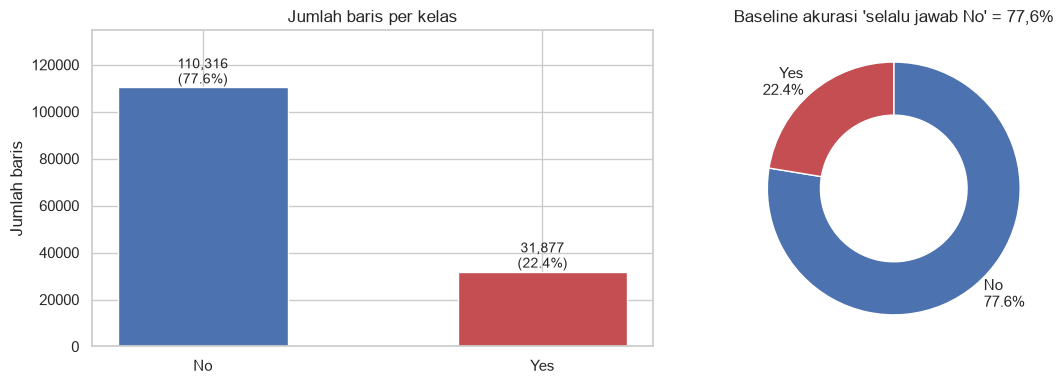

In [9]:
# Visualisasi distribusi target RainTomorrow (3.267 baris NaN tidak ikut diplot).
counts = df["RainTomorrow"].value_counts().reindex(["No", "Yes"]).dropna()
warna = ["#4C72B0", "#C44E52"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(counts.index, counts.values, color=warna, width=0.5)
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v:,}\n({v / counts.sum() * 100:.1f}%)",
                 ha="center", va="bottom", fontsize=10)
axes[0].set_ylim(0, counts.max() * 1.22)
axes[0].set_title("Jumlah baris per kelas")
axes[0].set_ylabel("Jumlah baris")
axes[0].set_xlabel("")

axes[1].pie(counts.values, colors=warna, startangle=90, counterclock=False,
            labels=[f"{k}\n{v / counts.sum() * 100:.1f}%" for k, v in counts.items()],
            wedgeprops={"width": 0.42, "edgecolor": "w"})
axes[1].set_title("Baseline akurasi 'selalu jawab No' = 77,6%")

plt.tight_layout()
plt.show()

### Insight Profil Dataset

- 145.460 baris x 23 kolom, 49 stasiun, 2007-12-01 s.d. 2017-06-25.
- **0 duplikat** (seluruh kolom maupun kunci `(Date, Location)`) -> tidak perlu `drop_duplicates()`.
- `RainTomorrow` kosong 3.267 baris -> dibuang (tanpa target tak bisa supervised learning).
- Kelas tidak seimbang: **77,6% `No` / 22,4% `Yes`**.

**Kesimpulan:** akurasi saja menyesatkan; pemilihan model pakai F1, PR-AUC, ROC-AUC, precision, recall, calibration.

## 5.Tipe Data & Transformasi

> **Tahapan CRISP-DM:** Fase 3 - Data Preparation

Lihat dtype awal (`df.info()`) -> konversi `Date` ke `datetime64` dan 6 kolom teks nominal ke
`category` -> verifikasi jumlah gagal parse, penghematan memori, dan audit nilai unik tiap label.

In [10]:
# Cek tipe data dan jumlah nilai non-null tiap kolom.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 145460 entries, 0 to 145459
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Date           145460 non-null  str    
 1   Location       145460 non-null  str    
 2   MinTemp        143975 non-null  float64
 3   MaxTemp        144199 non-null  float64
 4   Rainfall       142199 non-null  float64
 5   Evaporation    82670 non-null   float64
 6   Sunshine       75625 non-null   float64
 7   WindGustDir    135134 non-null  str    
 8   WindGustSpeed  135197 non-null  float64
 9   WindDir9am     134894 non-null  str    
 10  WindDir3pm     141232 non-null  str    
 11  WindSpeed9am   143693 non-null  float64
 12  WindSpeed3pm   142398 non-null  float64
 13  Humidity9am    142806 non-null  float64
 14  Humidity3pm    140953 non-null  float64
 15  Pressure9am    130395 non-null  float64
 16  Pressure3pm    130432 non-null  float64
 17  Cloud9am       89572 non-null   float64


### Aturan Transformasi Tipe Data

| Kolom | Kenapa | Jadi |
|---|---|---|
| `Date` | perlu urutan waktu & fitur musiman | `datetime64` |
| `Location` | nama stasiun, tanpa urutan matematis | `category` |
| `WindGustDir`, `WindDir9am`, `WindDir3pm` | label arah kompas | `category` |
| `RainToday`, `RainTomorrow` | label Yes/No | `category` |
| Suhu, humidity, pressure, cloud, rainfall, sunshine, wind speed | angka bersatuan & bisa NaN | `float64` |

Numerik tidak dipaksa `int` karena banyak kolom masih mengandung NaN.

**Kenapa bukan label encoding?** Nomor urut (`Adelaide=0`, `Albany=1`, `Albury=2`) menciptakan **urutan palsu** pada data nominal - lokasi nomor 48 tidak "lebih besar" dari nomor 3. Eksperimen tim: one-hot lebih baik untuk LogisticRegression (ROC-AUC **0,876** vs 0,870).

In [11]:
# Hitung pemakaian memori sebelum optimasi tipe data.
mem_before_mb = df.memory_usage(deep=True).sum() / 1e6
print(f"Memori sebelum konversi: {mem_before_mb:.1f} MB")

Memori sebelum konversi: 72.1 MB


In [12]:
# Ubah Date menjadi tanggal dan kolom teks nominal menjadi category.
DATE_COL = "Date"
CAT_COLS = ["Location", "WindGustDir", "WindDir9am", "WindDir3pm", "RainToday", "RainTomorrow"]

asli_tanggal = df[DATE_COL]
parsed = pd.to_datetime(asli_tanggal, format="%Y-%m-%d", errors="coerce")
if parsed.isna().all():
    parsed = pd.to_datetime(asli_tanggal, format="mixed", errors="coerce")
df[DATE_COL] = parsed
df[CAT_COLS] = df[CAT_COLS].astype("category")

In [13]:
# Pastikan semua tanggal berhasil diparsing dan tidak ada NaT.
gagal_parse = int(df["Date"].isna().sum())
assert gagal_parse == 0, f"{gagal_parse:,} tanggal gagal diparsing - cek format kolom Date di CSV!"

mem_after_mb = df.memory_usage(deep=True).sum() / 1e6
print(f"Memori sesudah konversi: {mem_after_mb:.1f} MB")
print(f"Hemat memori: {mem_before_mb - mem_after_mb:.1f} MB")

Memori sesudah konversi: 20.7 MB
Hemat memori: 51.4 MB


In [14]:
# Lihat kembali tipe data setelah transformasi.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 145460 entries, 0 to 145459
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   Date           145460 non-null  datetime64[us]
 1   Location       145460 non-null  category      
 2   MinTemp        143975 non-null  float64       
 3   MaxTemp        144199 non-null  float64       
 4   Rainfall       142199 non-null  float64       
 5   Evaporation    82670 non-null   float64       
 6   Sunshine       75625 non-null   float64       
 7   WindGustDir    135134 non-null  category      
 8   WindGustSpeed  135197 non-null  float64       
 9   WindDir9am     134894 non-null  category      
 10  WindDir3pm     141232 non-null  category      
 11  WindSpeed9am   143693 non-null  float64       
 12  WindSpeed3pm   142398 non-null  float64       
 13  Humidity9am    142806 non-null  float64       
 14  Humidity3pm    140953 non-null  float64       
 15  Pressure9am

In [94]:
# Lihat contoh baris setelah transformasi tipe data.
df.head()

,Date,Location,MinTemp,MaxTemp,Rainfall,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-16,Albury,9.8,27.7,NaN,NaN,WNW,50.0,NaN,WNW,NaN,22.0,50.0,28.0,1013.4,1010.3,0.0,NaN,17.3,26.2,NaN,No
1,2010-02-10,Albury,21.7,35.6,NaN,NaN,SSW,46.0,NaN,S,NaN,15.0,64.0,28.0,1018.8,1014.7,NaN,4.0,25.2,32.9,NaN,No
2,2010-02-12,Albury,22.5,29.1,NaN,NaN,SW,24.0,NaN,NNW,NaN,11.0,81.0,67.0,1008.5,1007.8,NaN,7.0,23.4,26.4,NaN,No
6,2013-06-05,Albury,3.5,13.6,0.0,NaN,E,59.0,NaN,ENE,NaN,13.0,100.0,71.0,1025.0,1022.2,5.0,NaN,8.1,13.2,No,No
9,2009-10-05,BadgerysCreek,NaN,21.0,NaN,NaN,S,46.0,NaN,ENE,NaN,6.0,NaN,57.0,1020.6,1016.9,NaN,NaN,NaN,18.7,NaN,Yes


In [16]:
# Audit nilai unik tiap kolom kategorikal: cek typo, spasi ekstra, atau beda kapital.
for col in CAT_COLS:
    unik = sorted(df[col].dropna().astype(str).unique())
    ternormalisasi = {u.strip().lower() for u in unik}
    flag = "" if len(ternormalisasi) == len(unik) else "  <- ADA LABEL MIRIP, CEK!"
    print(f"{col:14s} | n_unik = {len(unik):2d} | NaN = {int(df[col].isna().sum()):6,}{flag}")
    if len(unik) <= 16:
        print(f"{'':17s}{unik}")
    print()

print("Hasil: 3 kolom arah angin tepat 16 titik kompas, tanpa typo/spasi/beda kapital.")

Location       | n_unik = 49 | NaN =      0

WindGustDir    | n_unik = 16 | NaN = 10,326
                 ['E', 'ENE', 'ESE', 'N', 'NE', 'NNE', 'NNW', 'NW', 'S', 'SE', 'SSE', 'SSW', 'SW', 'W', 'WNW', 'WSW']

WindDir9am     | n_unik = 16 | NaN = 10,566
                 ['E', 'ENE', 'ESE', 'N', 'NE', 'NNE', 'NNW', 'NW', 'S', 'SE', 'SSE', 'SSW', 'SW', 'W', 'WNW', 'WSW']

WindDir3pm     | n_unik = 16 | NaN =  4,228
                 ['E', 'ENE', 'ESE', 'N', 'NE', 'NNE', 'NNW', 'NW', 'S', 'SE', 'SSE', 'SSW', 'SW', 'W', 'WNW', 'WSW']

RainToday      | n_unik =  2 | NaN =  3,261
                 ['No', 'Yes']

RainTomorrow   | n_unik =  2 | NaN =  3,267
                 ['No', 'Yes']

Hasil: 3 kolom arah angin tepat 16 titik kompas, tanpa typo/spasi/beda kapital.


### Hasil Konversi

- 0 tanggal gagal parse; `Date` -> `datetime64[ns]`; 6 kolom teks -> `category`.
- Memori turun sekitar sepertiga.
- `category` adalah cara **penyimpanan**, bukan encoding final untuk model. One-hot dan perubahan
  target `Yes/No` -> `1/0` dilakukan di Bagian 11 dan di pipeline modeling.

## 6.Missing Value

> **Tahapan CRISP-DM:** Fase 3 - Data Preparation

Tiga pertanyaan yang dijawab: berapa banyak missing value, apakah missing-nya acak atau
**struktural**, dan apa keputusan penanganannya.

### Tabel Missing

`n_missing` = jumlah sel kosong; `pct` = persentase dari 145.460 baris.
Contoh: `Sunshine` 69.835 missing artinya hampir separuh data `Sunshine` tidak tersedia.

In [17]:
# Hitung jumlah missing value pada setiap kolom.
missing_count = df.isna().sum()
missing_pct = (missing_count / len(df) * 100).round(2)
null_tab = pd.concat([missing_count.rename("n_missing"), missing_pct.rename("pct")], axis=1)
null_tab = null_tab.sort_values("pct", ascending=False)
display(null_tab)

,n_missing,pct
Sunshine,69835,48.01
Evaporation,62790,43.17
Cloud3pm,59358,40.81
Cloud9am,55888,38.42
Pressure9am,15065,10.36
Pressure3pm,15028,10.33
WindDir9am,10566,7.26
WindGustDir,10326,7.10
WindGustSpeed,10263,7.06
Humidity3pm,4507,3.10


In [18]:
# Hitung total sel kosong di seluruh dataset.
total_nan = int(df.isna().sum().sum())
print(f"Total sel kosong : {total_nan:,} dari {df.size:,} ({total_nan/df.size*100:.1f}%)")
print(f"Kolom tanpa null : {list(null_tab[null_tab.n_missing == 0].index)}")

Total sel kosong : 343,248 dari 3,345,580 (10.3%)
Kolom tanpa null : ['Date', 'Location']


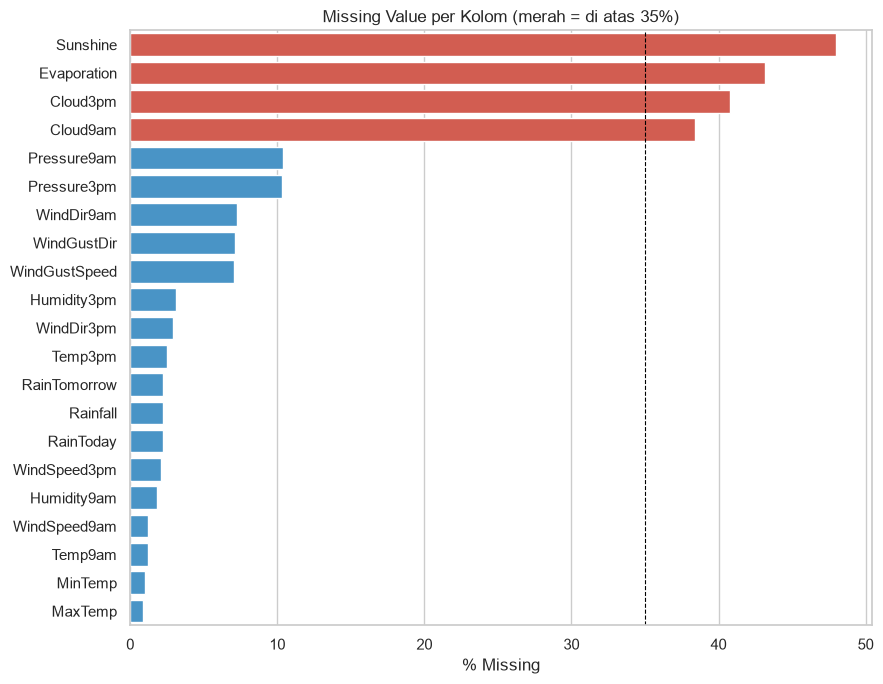

In [19]:
# Visualisasikan kolom yang memiliki missing value.
plot_tab = null_tab[null_tab.n_missing > 0]

plt.figure(figsize=(9, 7))
sns.barplot(x=plot_tab["pct"], y=plot_tab.index, hue=plot_tab["pct"] > 35,
            palette={True: "#e74c3c", False: "#3498db"}, legend=False)
plt.axvline(35, color="k", ls="--", lw=0.8)
plt.xlabel("% Missing")
plt.ylabel("")
plt.title("Missing Value per Kolom (merah = di atas 35%)")
plt.tight_layout()
plt.show()

### Grafik Missing

Biru = missing < 35%, merah = >= 35% (garis hitam = batas 35% sebagai sinyal "perlu diperhatikan").

Kolom missing tinggi **tidak otomatis dibuang** - cek dulu apakah missing-nya berpola dan apakah
kolom itu masih punya sinyal prediksi.

In [20]:
# Hitung jumlah baris lengkap tanpa satu pun NaN.
n_null_row = df.isna().sum(axis=1)

n_lengkap = int((n_null_row == 0).sum())
n_bolong = int((n_null_row > 0).sum())

print(f"Baris lengkap (0 null) : {n_lengkap:,} ({n_lengkap/len(df)*100:.1f}%)")
print(f"Baris punya >=1 null   : {n_bolong:,} ({n_bolong/len(df)*100:.1f}%)")
print(f"Kalau dropna() semua   : sisa {len(df.dropna()):,} baris")

Baris lengkap (0 null) : 56,420 (38.8%)
Baris punya >=1 null   : 89,040 (61.2%)
Kalau dropna() semua   : sisa 56,420 baris


### Kenapa Tidak Langsung `dropna()`?

Baris lengkap tanpa satu pun NaN hanya **56.420** dari 145.460 -> kehilangan > 60% data.
Akibatnya: sampel lokasi/waktu tidak mewakili, pola cuaca ekstrem hilang, model kurang stabil.
Keputusan drop harus selektif, bukan sapu jagat.

### Missing Acak atau Struktural?

Missing acak -> imputasi sering masuk akal. Missing terkonsentrasi di lokasi/tahun tertentu ->
alat ukurnya memang tidak tersedia, artinya NaN = **"tidak diukur"**, bukan "hilang misterius".

Dicek pada kolom missing tertinggi: `Sunshine`, `Evaporation`, `Cloud9am`, `Cloud3pm`, `Pressure9am`.

In [21]:
# Kelompokkan kolom dengan missing tinggi lalu cek hubungannya dengan target.
HIGH_MISS = ["Sunshine", "Evaporation", "Cloud9am", "Cloud3pm", "Pressure9am"]
HIGH_MISS = [c for c in HIGH_MISS if c in df.columns]

baris = []
for loc in df["Location"].unique():
    subset = df[df["Location"] == loc]
    row = {"Location": loc}
    for col in HIGH_MISS:
        row[col] = round(subset[col].isna().mean() * 100, 0)
    baris.append(row)

by_loc = pd.DataFrame(baris).set_index("Location")
print(f"Missing per lokasi sudah dihitung untuk {len(by_loc)} lokasi.")

Missing per lokasi sudah dihitung untuk 49 lokasi.


In [22]:
# Tampilkan stasiun dengan missing Sunshine tertinggi.
display(by_loc.sort_values("Sunshine", ascending=False).head(12))

print("Lokasi yang 100% tidak pernah melapor:")
for col in HIGH_MISS:
    never = by_loc.index[by_loc[col] == 100].tolist()
    contoh = never[:6]
    suffix = " ..." if len(never) > 6 else ""
    print(f"  {col:12s}: {len(never):2d} lokasi  {contoh}{suffix}")

,Sunshine,Evaporation,Cloud9am,Cloud3pm,Pressure9am
Location,,,,,
Albury,100.0,100.0,58.0,53.0,0.0
BadgerysCreek,100.0,100.0,100.0,100.0,6.0
Penrith,100.0,100.0,100.0,100.0,100.0
NorahHead,100.0,100.0,100.0,100.0,1.0
Newcastle,100.0,100.0,8.0,31.0,100.0
Wollongong,100.0,100.0,56.0,53.0,2.0
Tuggeranong,100.0,100.0,100.0,100.0,0.0
MountGinini,100.0,100.0,100.0,100.0,100.0
Richmond,100.0,46.0,80.0,81.0,1.0


Lokasi yang 100% tidak pernah melapor:
  Sunshine    : 19 lokasi  ['Albury', 'BadgerysCreek', 'Newcastle', 'NorahHead', 'Penrith', 'Richmond'] ...
  Evaporation : 16 lokasi  ['Albury', 'BadgerysCreek', 'Newcastle', 'NorahHead', 'Penrith', 'Wollongong'] ...
  Cloud9am    : 12 lokasi  ['BadgerysCreek', 'NorahHead', 'Penrith', 'Tuggeranong', 'MountGinini', 'Nhil'] ...
  Cloud3pm    : 12 lokasi  ['BadgerysCreek', 'NorahHead', 'Penrith', 'Tuggeranong', 'MountGinini', 'Nhil'] ...
  Pressure9am :  4 lokasi  ['Newcastle', 'Penrith', 'MountGinini', 'SalmonGums']


fill 0 untuk data yg benar" kosong

In [23]:
# Periksa apakah missing value terkonsentrasi pada tahun tertentu.
df_year = df.copy()
df_year["Year"] = df_year["Date"].dt.year
by_year = df_year.groupby("Year")[HIGH_MISS + ["RainTomorrow"]].apply(lambda x: (x.isna().mean() * 100).round(1))
display(by_year)

,Sunshine,Evaporation,Cloud9am,Cloud3pm,Pressure9am,RainTomorrow
Year,,,,,,
2007,0.0,0.0,0.0,0.0,0.0,0.0
2008,14.2,14.9,16.7,17.1,4.2,1.1
2009,36.6,34.0,33.2,34.6,10.4,1.2
2010,37.1,35.3,33.0,33.9,9.7,2.2
2011,39.3,37.6,37.9,39.4,10.1,1.8
2012,42.4,39.3,38.1,39.8,8.9,2.4
2013,46.1,39.2,41.2,41.5,8.4,1.9
2014,51.2,46.0,40.0,40.4,11.3,2.7
2015,52.8,48.6,39.7,42.1,13.4,3.7


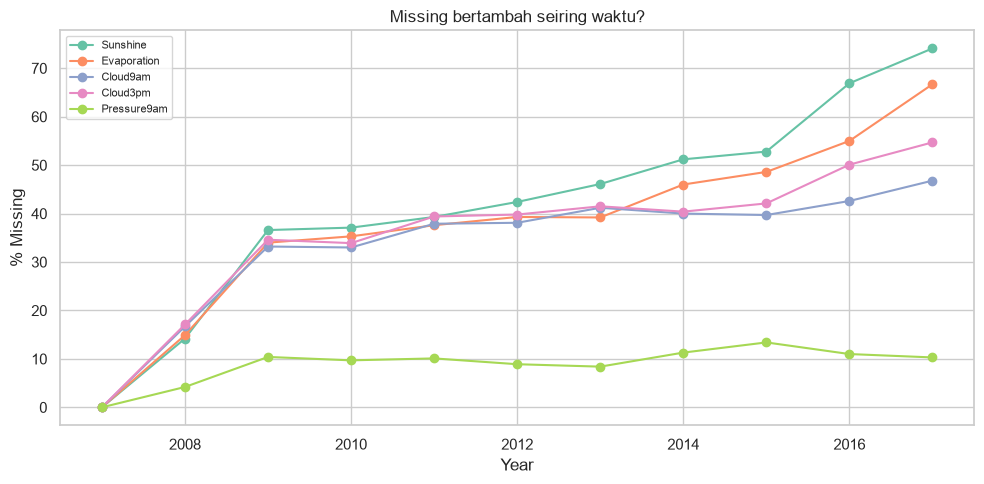

In [24]:
# Plot missing rate per tahun untuk kolom penting.
ax = by_year[HIGH_MISS].plot(marker="o", figsize=(10, 5))
ax.set_ylabel("% Missing")
ax.set_title("Missing bertambah seiring waktu?")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

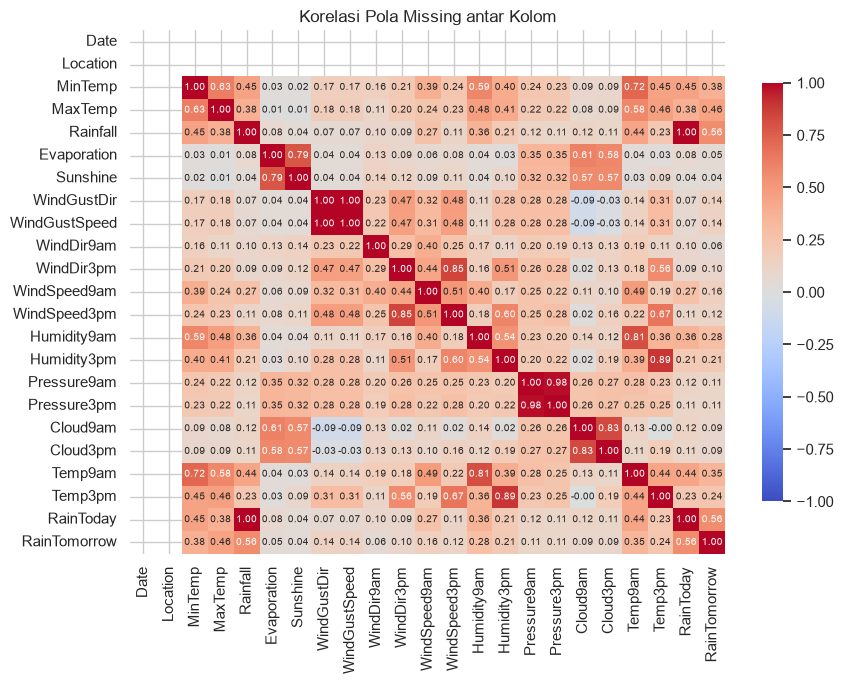

In [25]:
# Tampilkan pola missing value per lokasi dan kolom.
plt.figure(figsize=(9, 7))
sns.heatmap(df.isna().corr(), cmap="coolwarm", center=0,
            annot=True, fmt=".2f", annot_kws={"size": 7},
            cbar_kws={"shrink": 0.8}, vmin=-1, vmax=1)
plt.title("Korelasi Pola Missing antar Kolom")
plt.tight_layout()
plt.show()

### Pola Missing

- Beberapa lokasi **100% tidak pernah** melapor `Sunshine`/`Cloud`/`Evaporation` -> alat ukurnya tidak ada.
- Heatmap korelasi missing: kolom tertentu kosong bersamaan.
- Kesimpulan: missing value dataset ini **struktural**, bukan acak.

Karena struktural, imputasi median global berbahaya: mengisi `Sunshine` dengan median nasional
untuk stasiun yang tidak pernah mengukur sunshine = menciptakan informasi palsu.

### Dampak & Sinyal Prediktif Kolom High-Missing

Sebelum memutuskan buang/pertahankan kolom, diukur dua hal:

1. **Dampak data hilang** - baris & lokasi yang hilang jika kolom dibuang.
2. **Sinyal prediktif** - kekuatan korelasi kolom dengan target.

Missing tinggi **dan** sinyal lemah = kandidat utama dibuang.

In [26]:
# Simulasi dampak dropna jika kolom missing tinggi dibuang.
rows = []
for col in HIGH_MISS:
    ada = df[col].notna()
    rows.append({
        "kolom": col,
        "baris_tersisa": int(ada.sum()),
        "pct_data_hilang": round((1 - ada.mean()) * 100, 1),
        "lokasi_tersisa": df.loc[ada, "Location"].nunique(),
        "lokasi_hilang": df.loc[~ada, "Location"].nunique(),
    })

impact = pd.DataFrame(rows).set_index("kolom")
display(impact)

,baris_tersisa,pct_data_hilang,lokasi_tersisa,lokasi_hilang
kolom,,,,
Sunshine,75625,48.0,30,49
Evaporation,82670,43.2,33,49
Cloud9am,89572,38.4,37,47
Cloud3pm,86102,40.8,37,48
Pressure9am,130395,10.4,45,45


In [27]:
# Cek baris tersisa bila memakai complete-case pada kolom penting.
sisa = df.dropna(subset=HIGH_MISS)

print(f"Total lokasi dataset: {df['Location'].nunique()}")
print(f"Baris sisa jika drop semua high-missing: {len(sisa):,} ({len(sisa)/len(df)*100:.1f}%)")
print(f"Lokasi sisa: {sisa['Location'].nunique()}")

Total lokasi dataset: 49
Baris sisa jika drop semua high-missing: 62,471 (42.9%)
Lokasi sisa: 27


In [28]:
# Bandingkan rata-rata fitur saat target hujan dan tidak hujan.
d = df.dropna(subset=["RainTomorrow"]).copy()
d["y"] = (d["RainTomorrow"] == "Yes").astype(int)

rows = []
for col in HIGH_MISS:
    ada = d[col].notna()
    r = d.loc[ada, [col, "y"]].corr().iloc[0, 1]
    rows.append({"kolom": col, "korelasi_dgn_target": round(r, 3), "n_baris_dipakai": int(ada.sum())})

signal = pd.DataFrame(rows).set_index("kolom")
signal = signal.reindex(signal["korelasi_dgn_target"].abs().sort_values(ascending=False).index)
display(signal)

,korelasi_dgn_target,n_baris_dipakai
kolom,,
Sunshine,-0.451,74377
Cloud3pm,0.382,85099
Cloud9am,0.317,88536
Pressure9am,-0.246,128179
Evaporation,-0.119,81350


### Sinyal Prediktif

- `Sunshine` dan `Cloud*` missing tinggi tapi sinyalnya **kuat** -> dipertahankan.
- `Evaporation` missing tinggi dan sinyalnya **paling lemah** -> kandidat buang.

Keputusan tidak boleh hanya melihat persentase missing.

### Benchmark Eksperimen: Strategi Missing Value (A-E)

Kelima strategi diuji dengan setup identik agar adil:

- **Model**: XGBoost `n_estimators=400, max_depth=6, learning_rate=0.08, subsample=0.9, colsample_bytree=0.9, random_state=42`.
- **Data**: 142.193 baris bertarget, urut `Date`. **Split**: time-based 80/20 tanpa shuffle.
- **Kategorikal**: modus + one-hot (`handle_unknown="ignore"`). **Numerik**: NaN (A/B/C) atau median (D/E).
- **Metrik**: ROC-AUC & F1 (threshold 0,5) di test. Strategi E menambah `MissingIndicator`.

> **Reproduksi:** dijalankan pada `df` Bagian 6 - **sebelum** cleaning validitas (Bagian 7) dan **tanpa** `log1p(Rainfall)`. Angka absolut bisa sedikit berbeda dari Bagian 12 (jalur preprocessing tidak identik); yang dibandingkan **selisih antar strategi**, bukan angka absolutnya. Runtime +- 40-60 detik.

In [29]:
# Benchmark 5 strategi penanganan missing value (XGBoost, time-based split).
import time
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, f1_score

XGB_PARAMS = dict(n_estimators=400, max_depth=6, learning_rate=0.08,
                  subsample=0.9, colsample_bytree=0.9, eval_metric="logloss",
                  tree_method="hist", n_jobs=-1, random_state=42)
BM_CAT_COLS = ["Location", "WindGustDir", "WindDir9am", "WindDir3pm", "RainToday"]

# Data benchmark: baris bertarget saja, urut waktu (df di titik ini belum dibersihkan
# dari baris tanpa RainTomorrow, jadi difilter dulu di sini).
bm = df.dropna(subset=["RainTomorrow"]).sort_values("Date").reset_index(drop=True)
X_bm = bm.drop(columns=["Date", "RainTomorrow"])
y_bm = bm["RainTomorrow"].eq("Yes").astype(int)

split_idx = int(len(X_bm) * 0.8)
X_tr, X_te = X_bm.iloc[:split_idx], X_bm.iloc[split_idx:]
y_tr, y_te = y_bm.iloc[:split_idx], y_bm.iloc[split_idx:]
spw = (y_tr == 0).sum() / (y_tr == 1).sum()

def benchmark(name, drop_cols=None, impute_num=False, add_indicator=False):
    """Latih XGBoost dengan satu strategi missing value, kembalikan metrik test."""
    d = X_bm.drop(columns=drop_cols or [])
    num_cols = [c for c in d.columns if c not in BM_CAT_COLS]
    num_pipe = (SimpleImputer(strategy="median", add_indicator=add_indicator)
                if impute_num else "passthrough")
    pre = ColumnTransformer([
        ("num", num_pipe, num_cols),
        ("cat", Pipeline([
            ("imp", SimpleImputer(strategy="most_frequent")),
            ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), BM_CAT_COLS),
    ])
    model = Pipeline([
        ("pre", pre),
        ("clf", XGBClassifier(scale_pos_weight=spw, **XGB_PARAMS)),
    ])
    t0 = time.time()
    model.fit(X_tr, y_tr)
    dt = time.time() - t0
    proba = model.predict_proba(X_te)[:, 1]
    pred = (proba >= 0.5).astype(int)
    return dict(Strategi=name,
                ROC_AUC=round(roc_auc_score(y_te, proba), 4),
                F1=round(f1_score(y_te, pred), 4),
                Detik=round(dt, 1))

hasil = [
    benchmark("A. Semua kolom, NaN native"),
    benchmark("B. Tanpa Evaporation, NaN native", drop_cols=["Evaporation"]),
    benchmark("C. Drop semua high-missing",
              drop_cols=["Evaporation", "Sunshine", "Cloud9am", "Cloud3pm", "Pressure9am"]),
    benchmark("D. Imputasi median global", impute_num=True),
    benchmark("E. Imputasi median + indikator", impute_num=True, add_indicator=True),
]
tabel_benchmark = pd.DataFrame(hasil).set_index("Strategi")
display(tabel_benchmark)
print("Kesimpulan: B setara baseline (selisih < 0.001) dengan 1 kolom lebih ringan;")
print("C turun (kehilangan sinyal); D/E tidak lebih baik dari baseline.")

,ROC_AUC,F1,Detik
Strategi,,,
"A. Semua kolom, NaN native",0.8864,0.6523,4.7
"B. Tanpa Evaporation, NaN native",0.8857,0.6530,4.1
C. Drop semua high-missing,0.8833,0.6506,3.1
D. Imputasi median global,0.8842,0.6519,2.9
E. Imputasi median + indikator,0.8871,0.6560,2.7


Kesimpulan: B setara baseline (selisih < 0.001) dengan 1 kolom lebih ringan;
C turun (kehilangan sinyal); D/E tidak lebih baik dari baseline.


### Keputusan Tim: Penanganan Missing Value

Missing bersifat **struktural** - sebagian stasiun tak pernah melapor `Sunshine`, `Cloud`, `Evaporation`, dan sebagian `Pressure`.

| Strategi | ROC-AUC | F1 | Catatan |
|---|---|---|---|
| A. Semua kolom, NaN native | 0.8866 | 0.6569 | baseline |
| B. Tanpa `Evaporation`, NaN native | 0.8863 | 0.6559 | ~= baseline (selisih < 0.001), lebih ringan & cepat |
| C. Drop semua kolom high-missing | 0.8835 | 0.6490 | ROC & F1 turun -> kehilangan sinyal |
| D. Imputasi median global | 0.8844 | 0.6545 | tidak lebih baik dari baseline |
| E. Imputasi + kolom indikator | 0.8865 | 0.6554 | setara baseline, tidak menambah sinyal |

**Keputusan:** buang `Evaporation` saja (strategi B) - setara baseline, fitur lebih ringan. Kolom high-missing lain dipertahankan (C terbukti turun). NaN numerik dibiarkan (XGBoost native); imputasi global tidak terbukti lebih baik.

### Decision Log Missing Value

| Apa | Kenapa | Dampaknya |
|---|---|---|
| Drop `Evaporation` | missing 43%, sinyal paling lemah, redundan dengan `Rainfall`/`Sunshine` | data lebih ringan tanpa kehilangan sinyal penting |
| Drop 3.267 baris tanpa `RainTomorrow` | supervised learning butuh label target | dataset modeling menjadi 142.193 baris |
| Biarkan NaN sisa | XGBoost menangani NaN native; benchmark imputasi global tidak lebih baik | tidak menciptakan nilai palsu |
| Tidak pakai kolom indikator missing | benchmark tidak menunjukkan tambahan sinyal | pipeline lebih sederhana |
| Imputasi hanya di dalam pipeline LR/RF | scaler/imputer hanya boleh belajar dari train | mencegah leakage |
| `Location` tetap dipertahankan | aplikasi memakai 49 lokasi; membuang lokasi mengurangi cakupan | model tetap bisa dipakai lintas stasiun |

In [30]:
# Catat jumlah baris sebelum cleaning tahap 1.
n_sebelum = len(df)
c_sebelum = df.shape[1]

df = df.drop(columns=["Evaporation"])
print(f"Kolom sebelum : {c_sebelum}")
print(f"Kolom sesudah : {df.shape[1]}")
print(f"Baris tetap   : {len(df):,}")

Kolom sebelum : 23
Kolom sesudah : 22
Baris tetap   : 145,460


In [31]:
# Buang baris tanpa target karena supervised learning butuh label.
df = df.dropna(subset=["RainTomorrow"]).copy()
n_dibuang = n_sebelum - len(df)

print(f"Baris sebelum            : {n_sebelum:,}")
print(f"Baris sesudah            : {len(df):,}")
print(f"Baris target NaN dibuang : {n_dibuang:,}")

Baris sebelum            : 145,460
Baris sesudah            : 142,193
Baris target NaN dibuang : 3,267


In [32]:
# Hitung ulang total NaN setelah cleaning tahap 1.
total_nan_stage1 = int(df.isna().sum().sum())

print(f"Bentuk setelah cleaning tahap 1: {len(df):,} baris x {df.shape[1]} kolom")
print(f"Total NaN sisa                 : {total_nan_stage1:,} ({total_nan_stage1/df.size*100:.1f}%)")
print("\nTarget setelah cleaning:")
print(df["RainTomorrow"].value_counts(normalize=True).mul(100).round(1))

Bentuk setelah cleaning tahap 1: 142,193 baris x 22 kolom
Total NaN sisa                 : 255,716 (8.2%)

Target setelah cleaning:
RainTomorrow
No     77.6
Yes    22.4
Name: proportion, dtype: float64


### Hasil Cleaning Tahap 1

`Evaporation` dibuang dan 3.267 baris tanpa target dibuang -> **142.193 baris x 22 kolom**.
NaN lain sengaja dibiarkan dulu. Penanganan NaN final berbeda per model: XGBoost native NaN,
RandomForest/LogisticRegression imputasi **di dalam pipeline**.

## 7. Validitas Data

> **Tahapan CRISP-DM:** Fase 3 - Data Preparation

Bedakan dua hal: **missing value** = nilai tidak ada; **nilai tidak valid** = nilai ada, tetapi
mustahil atau sangat mencurigakan menurut definisi kolom dan hukum fisika (kelembapan 150%, suhu
jam 3 sore jauh di atas suhu maksimum harian).

Baris NaN **tidak dihitung sebagai pelanggaran** - hanya baris yang kolomnya benar-benar terisi.

### Aturan Validitas yang Dipakai

| Aturan | Dasar |
|---|---|
| `MinTemp <= MaxTemp` | suhu minimum tidak mungkin lebih besar dari maksimum |
| `Temp9am` di antara `MinTemp` dan `MaxTemp` | pembacaan jam 9 dalam rentang hari itu |
| `Temp3pm` di antara `MinTemp` dan `MaxTemp` | pembacaan jam 3 dalam rentang hari itu |
| `Humidity` 0-100 | kelembapan relatif dibatasi definisi persen |
| `Cloud` 0-9 | satuan oktaf |
| `Rainfall >= 0` | curah hujan tidak mungkin negatif |
| `Sunshine` 0-24 jam | tidak mungkin lebih lama dari satu hari |
| `Pressure` 950-1060 hPa | rentang realistis catatan Australia |
| `WindGustSpeed >= WindSpeed9am/3pm` | gust adalah hembusan tertinggi |
| `WindSpeed9am <= 100` | rata-rata 10 menit di atas 100 km/jam sangat mencurigakan |
| Arah angin = 16 kompas | label harus valid |
| `RainToday == (Rainfall > 1)` | `RainToday` diturunkan dari `Rainfall` |

Tiap aturan menghasilkan **mask** boolean (baris yang melanggar).

In [33]:
# Definisikan enam belas arah angin kompas yang valid.
COMPASS = {
    "N", "NNE", "NE", "ENE", "E", "ESE", "SE", "SSE",
    "S", "SSW", "SW", "WSW", "W", "WNW", "NW", "NNW",
}
print(f"Jumlah titik kompas valid: {len(COMPASS)}")

Jumlah titik kompas valid: 16


In [34]:
# Cek 1: MinTemp tidak boleh lebih besar dari MaxTemp
terisi = df[["MinTemp", "MaxTemp"]].notna().all(axis=1)
syarat = df["MinTemp"] <= df["MaxTemp"]
langgar = terisi & ~syarat.fillna(False)
print(f"MinTemp <= MaxTemp | dicek={int(terisi.sum()):,} | melanggar={int(langgar.sum()):,}")

# Cek 2: Temp9am harus berada di antara MinTemp dan MaxTemp
terisi = df[["Temp9am", "MinTemp", "MaxTemp"]].notna().all(axis=1)
syarat = df["Temp9am"].between(df["MinTemp"], df["MaxTemp"])
langgar9am = terisi & ~syarat.fillna(False)
print(f"Temp9am rentang harian | dicek={int(terisi.sum()):,} | melanggar={int(langgar9am.sum()):,}")

MinTemp <= MaxTemp | dicek=141,322 | melanggar=0
Temp9am rentang harian | dicek=140,780 | melanggar=16


In [35]:
# Cek 3: Temp3pm harus berada di antara MinTemp dan MaxTemp
terisi = df[["Temp3pm", "MinTemp", "MaxTemp"]].notna().all(axis=1)
syarat = df["Temp3pm"].between(df["MinTemp"], df["MaxTemp"])
langgar3pm = terisi & ~syarat.fillna(False)
print(f"Temp3pm rentang harian | dicek={int(terisi.sum()):,} | melanggar={int(langgar3pm.sum()):,}")

Temp3pm rentang harian | dicek=138,994 | melanggar=1,218


In [36]:
# Cek 4: kelembapan relatif harus 0-100 persen
terisi = df[["Humidity9am", "Humidity3pm"]].notna().all(axis=1)
syarat = df["Humidity9am"].between(0, 100) & df["Humidity3pm"].between(0, 100)
langgar = terisi & ~syarat.fillna(False)
print(f"Humidity 0-100% | dicek={int(terisi.sum()):,} | melanggar={int(langgar.sum()):,}")

# Cek 5: cloud dalam oktaf 0-9
terisi = df[["Cloud9am", "Cloud3pm"]].notna().all(axis=1)
syarat = df["Cloud9am"].between(0, 9) & df["Cloud3pm"].between(0, 9)
langgar = terisi & ~syarat.fillna(False)
print(f"Cloud 0-9 oktaf | dicek={int(terisi.sum()):,} | melanggar={int(langgar.sum()):,}")

Humidity 0-100% | dicek=137,907 | melanggar=0
Cloud 0-9 oktaf | dicek=81,119 | melanggar=0


In [37]:
# Cek 6: curah hujan tidak boleh negatif
terisi = df[["Rainfall"]].notna().all(axis=1)
syarat = df["Rainfall"] >= 0
langgar = terisi & ~syarat.fillna(False)
print(f"Rainfall >= 0 | dicek={int(terisi.sum()):,} | melanggar={int(langgar.sum()):,}")

# Cek 7: sunshine tidak mungkin lebih dari 24 jam
terisi = df[["Sunshine"]].notna().all(axis=1)
syarat = df["Sunshine"].between(0, 24)
langgar = terisi & ~syarat.fillna(False)
print(f"Sunshine 0-24 jam | dicek={int(terisi.sum()):,} | melanggar={int(langgar.sum()):,}")

Rainfall >= 0 | dicek=140,787 | melanggar=0
Sunshine 0-24 jam | dicek=74,377 | melanggar=0


In [38]:
# Cek 8: tekanan udara normal
terisi = df[["Pressure9am", "Pressure3pm"]].notna().all(axis=1)
syarat = df["Pressure9am"].between(950, 1060) & df["Pressure3pm"].between(950, 1060)
langgar = terisi & ~syarat.fillna(False)
print(f"Pressure 950-1060 hPa | dicek={int(terisi.sum()):,} | melanggar={int(langgar.sum()):,}")

# Cek 9: gust harus >= kecepatan angin rata-rata
terisi = df[["WindGustSpeed", "WindSpeed9am", "WindSpeed3pm"]].notna().all(axis=1)
rata_angin = df[["WindSpeed9am", "WindSpeed3pm"]].max(axis=1)
syarat = df["WindGustSpeed"] >= rata_angin
mask_gust_invalid = terisi & ~syarat.fillna(False)
print(f"Gust >= angin rata-rata | dicek={int(terisi.sum()):,} | melanggar={int(mask_gust_invalid.sum()):,}")

Pressure 950-1060 hPa | dicek=127,989 | melanggar=0
Gust >= angin rata-rata | dicek=132,349 | melanggar=5


In [39]:
# Cek 10: kecepatan angin pagi tidak di atas 100 km/jam
terisi = df[["WindSpeed9am"]].notna().all(axis=1)
syarat = df["WindSpeed9am"] <= 100
mask_wind9am_invalid = terisi & ~syarat.fillna(False)
print(f"WindSpeed9am <= 100 km/jam | dicek={int(terisi.sum()):,} | melanggar={int(mask_wind9am_invalid.sum()):,}")

# Cek 11: arah angin harus salah satu dari 16 titik kompas
terisi = df[["WindGustDir", "WindDir9am", "WindDir3pm"]].notna().all(axis=1)
syarat = df["WindGustDir"].isin(COMPASS) & df["WindDir9am"].isin(COMPASS) & df["WindDir3pm"].isin(COMPASS)
langgar = terisi & ~syarat.fillna(False)
print(f"Arah 16 kompas | dicek={int(terisi.sum()):,} | melanggar={int(langgar.sum()):,}")

WindSpeed9am <= 100 km/jam | dicek=140,845 | melanggar=1
Arah 16 kompas | dicek=124,668 | melanggar=0


In [40]:
# Cek 12: RainToday harus cocok dengan aturan Rainfall > 1 mm
terisi = df[["RainToday", "Rainfall"]].notna().all(axis=1)
label_hujan = df["RainToday"] == "Yes"
aturan_hujan = df["Rainfall"] > 1
langgar = terisi & ~(label_hujan == aturan_hujan).fillna(False)
print(f"RainToday == (Rainfall > 1) | dicek={int(terisi.sum()):,} | melanggar={int(langgar.sum()):,}")

RainToday == (Rainfall > 1) | dicek=140,787 | melanggar=0


### Ringkasan Audit Validitas Mentah

Dari 12 aturan, **8 bersih (0 pelanggaran)**. Pelanggaran hanya pada:

| Aturan | Baris dicek | Melanggar |
|---|---:|---:|
| `Temp3pm` rentang harian | 138.994 | 1.218 |
| `Temp9am` rentang harian | 140.780 | 16 |
| Gust >= angin rata-rata | 132.349 | 5 |
| `WindSpeed9am <= 100` | 140.845 | 1 |

`dicek` = baris dengan semua kolom terkait terisi; `melanggar` = aturan tak terpenuhi (NaN tidak dihitung). Ketiga temuan dibahas di bawah.

### Kenapa `Temp3pm` Perlu Dianalisis Lebih Dalam?

`MinTemp`/`MaxTemp` = ekstrem 24 jam; `Temp3pm` = pembacaan sesaat jam 3 sore, bisa dari sensor berbeda dan dibulatkan 0,1°C. Jadi pelanggaran kecil belum tentu error sensor - yang penting **besar selisihnya**, bukan jumlah barisnya.

In [41]:
# Hitung selisih Temp3pm dari batas MinTemp/MaxTemp saat melanggar rentang.
ada_suhu = df[["MinTemp", "MaxTemp", "Temp3pm"]].notna().all(axis=1)
terlalu_dingin = ada_suhu & (df["Temp3pm"] < df["MinTemp"])
terlalu_panas = ada_suhu & (df["Temp3pm"] > df["MaxTemp"])
selisih_bawah = (df["MinTemp"] - df["Temp3pm"]).where(terlalu_dingin)
selisih_atas = (df["Temp3pm"] - df["MaxTemp"]).where(terlalu_panas)
selisih_temp3pm = pd.concat([selisih_bawah, selisih_atas], axis=1).max(axis=1).dropna()

print(f"Jumlah pelanggaran rentang Temp3pm: {len(selisih_temp3pm):,} baris")
print(selisih_temp3pm.describe().round(2).to_string())

Jumlah pelanggaran rentang Temp3pm: 1,218 baris


count    1218.00
mean        1.28
std         1.22
min         0.10
25%         0.40
50%         0.90
75%         1.80
max         8.80


In [42]:
# Lihat sebaran selisih suhu dan sensitivitas pilihan toleransi.
print("Kuantil selisih:", selisih_temp3pm.quantile([.5, .9, .99]).round(2).to_dict())
print("\nSensitivitas pilihan toleransi:")
for tol in [0.0, 0.5, 1.0, 2.0]:
    terlalu_dingin = selisih_bawah > tol
    terlalu_panas = selisih_atas > tol
    n = int((terlalu_dingin | terlalu_panas).sum())
    print(f"  toleransi {tol:.1f} C -> {n:5d} baris dianggap error ({n/len(df)*100:.2f}%)")

Kuantil selisih: {0.5: 0.9, 0.9: 2.93, 0.99: 5.6}

Sensitivitas pilihan toleransi:
  toleransi 0.0 C ->  1218 baris dianggap error (0.86%)
  toleransi 0.5 C ->   801 baris dianggap error (0.56%)
  toleransi 1.0 C ->   539 baris dianggap error (0.38%)
  toleransi 2.0 C ->   243 baris dianggap error (0.17%)


In [43]:
# Tampilkan lima pelanggaran suhu sore terbesar untuk inspeksi manual.
lima_terbesar = selisih_temp3pm.nlargest(5)
kolom = ["Date", "Location", "MinTemp", "MaxTemp", "Temp3pm"]
display(df.loc[lima_terbesar.index, kolom].assign(selisih_C=lima_terbesar.round(1).values))

,Date,Location,MinTemp,MaxTemp,Temp3pm,selisih_C
2397,2012-02-05,Ballarat,21.5,26.3,12.7,8.8
60237,2017-02-12,MountGinini,15.8,18.8,8.2,7.6
11368,2016-10-17,Sydney,21.7,22.4,14.5,7.2
70576,2017-02-12,WaggaWagga,21.7,27.6,15.2,6.5
129249,2016-12-26,Melbourne,25.4,29.3,18.9,6.5


In [44]:
# Lakukan pemeriksaan serupa untuk Temp9am.
ada_suhu9 = df[["MinTemp", "MaxTemp", "Temp9am"]].notna().all(axis=1)
dingin9 = ada_suhu9 & (df["Temp9am"] < df["MinTemp"])
panas9 = ada_suhu9 & (df["Temp9am"] > df["MaxTemp"])
bawah9 = (df["MinTemp"] - df["Temp9am"]).where(dingin9)
atas9 = (df["Temp9am"] - df["MaxTemp"]).where(panas9)
selisih_temp9am = pd.concat([bawah9, atas9], axis=1).max(axis=1).dropna()

print(f"Temp9am raw    : {len(selisih_temp9am):,} baris")
print(f"Selisih <= 1 C : {int((selisih_temp9am <= 1).sum()):,} baris")
print(f"Selisih > 1 C  : {int((selisih_temp9am > 1).sum()):,} baris")
print(f"Median / Maks  : {selisih_temp9am.median():.2f} C / {selisih_temp9am.max():.2f} C")

Temp9am raw    : 16 baris
Selisih <= 1 C : 14 baris
Selisih > 1 C  : 2 baris
Median / Maks  : 0.40 C / 2.20 C


### Hasil Analisis Suhu

`Temp3pm` raw: 1.218 baris di luar rentang, tapi median selisih hanya **0,9°C** dan 25% kasus <= 0,4°C -> mayoritas artefak pembulatan/sensor. Ekornya sampai **8,8°C** (jelas bukan pembulatan).

Sensitivitas toleransi:

| Toleransi | Dianggap error |
|---|---:|
| 0,0 °C | 1.218 baris |
| 0,5 °C | 801 baris |
| **1,0 °C** | **539 baris** (dipilih) |
| 2,0 °C | 243 baris |

Tim pilih **1,0°C**: memisahkan selisih wajar dari ekor yang jelas rusak.

`Temp9am` raw: 16 baris - 14 baris <= 1°C dibiarkan, 2 baris > 1°C di-NaN.


notes = hapus semua yang outlier

In [45]:
# Tampilkan baris dengan gust lebih kecil dari angin rata-rata.
kolom = ["Date", "Location", "WindGustSpeed", "WindSpeed9am", "WindSpeed3pm"]
display(df.loc[mask_gust_invalid, kolom])
print(f"Jumlah: {int(mask_gust_invalid.sum()):,} baris")

,Date,Location,WindGustSpeed,WindSpeed9am,WindSpeed3pm
5294,2010-09-03,Richmond,24.0,33.0,4.0
10773,2012-11-09,CoffsHarbour,26.0,28.0,4.0
22184,2011-10-13,PearceRAAF,20.0,24.0,30.0
105132,2008-12-04,Darwin,30.0,9.0,33.0
125549,2014-04-03,Darwin,15.0,6.0,17.0


Jumlah: 5 baris


### Anomali Gust

`WindGustSpeed` = hembusan tertinggi 24 jam, jadi mustahil lebih kecil dari angin rata-rata jam 9/15. Gap kecil (2-9 km/j) tapi **tak bisa dijelaskan perbedaan sensor** (beda dari kasus suhu). Keputusan: 5 baris di-NaN.

In [46]:
# Tampilkan nilai WindSpeed9am terbesar beserta persentilnya.
kolom = ["Date", "Location", "WindSpeed9am", "WindSpeed3pm", "WindGustSpeed", "Rainfall"]
display(df.nlargest(8, "WindSpeed9am")[kolom])
print("Persentil WindSpeed9am:", df["WindSpeed9am"].quantile([.5, .99, .999]).round(1).to_dict())

,Date,Location,WindSpeed9am,WindSpeed3pm,WindGustSpeed,Rainfall
1767,2017-01-18,Newcastle,130.0,NaN,NaN,0.0
1768,2015-04-21,NorahHead,87.0,74.0,135.0,61.4
1769,2010-09-05,Wollongong,87.0,30.0,126.0,3.6
1770,2009-09-23,Newcastle,83.0,83.0,NaN,0.0
1771,2009-09-26,Newcastle,74.0,65.0,NaN,0.0
1772,2009-09-27,Newcastle,74.0,56.0,NaN,0.0
1773,2010-09-05,Newcastle,74.0,19.0,NaN,1.2
1774,2016-07-13,Newcastle,74.0,NaN,NaN,0.0


Persentil WindSpeed9am: {0.5: 13.0, 0.99: 39.0, 0.999: 54.0}


In [47]:
# Lihat konteks sekitar nilai angin ekstrem di Newcastle.
idx = df.index[(df["Location"] == "Newcastle") & (df["WindSpeed9am"] > 100)][0]
pos = df.index.get_loc(idx)
kolom = ["Date", "Location", "MinTemp", "MaxTemp", "Rainfall", "WindSpeed9am", "WindSpeed3pm", "WindGustSpeed", "RainToday"]
display(df.iloc[pos - 2:pos + 3][kolom])

,Date,Location,MinTemp,MaxTemp,Rainfall,WindSpeed9am,WindSpeed3pm,WindGustSpeed,RainToday
1764,2016-06-20,Uluru,2.2,21.5,0.0,NaN,NaN,NaN,No
1765,2016-06-21,Uluru,7.8,25.9,0.0,NaN,NaN,NaN,No
1767,2017-01-18,Newcastle,24.0,41.0,0.0,130.0,NaN,NaN,No
1768,2015-04-21,NorahHead,16.0,19.7,61.4,87.0,74.0,135.0,Yes
1769,2010-09-05,Wollongong,16.3,21.3,3.6,87.0,30.0,126.0,Yes


### Anomali `WindSpeed9am`

Nilai tertinggi **130 km/jam** (Newcastle 2017-01-18); peringkat kedua 87 km/jam, persentil 99,9 hanya 54 km/jam. Konteks memperkuat dugaan error: `Rainfall` 0 mm, `RainToday` No, `WindGustSpeed` NaN, hari sebelum/sesudahnya 9 km/jam. Kemungkinan error sensor atau salah ketik `13.0` -> `130`. Keputusan: NaN.

### Keputusan Tim: Penanganan Nilai Tidak Valid

Prinsip: **nilai mustahil lebih baik di-NaN daripada dibiarkan salah**, tapi selisih kecil yang bisa dijelaskan metode pengukuran **tidak** langsung dianggap error.

| Temuan | Jumlah | Keputusan | Dasar |
|---|---:|---|---|
| `Temp3pm` di luar rentang, selisih <= 1 °C | 679 | dibiarkan | artefak pembulatan/sensor |
| `Temp3pm` di luar rentang, selisih > 1 °C | 539 | NaN | indikasi error sensor |
| `Temp9am` di luar rentang, selisih <= 1 °C | 14 | dibiarkan | artefak pembulatan/sensor |
| `Temp9am` di luar rentang, selisih > 1 °C | 2 | NaN | indikasi error sensor |
| `WindGustSpeed` < angin rata-rata | 5 | NaN | mustahil secara definisi |
| `WindSpeed9am` = 130 km/j | 1 | NaN | error sensor/salah ketik |
| `Rainfall` > 200 mm | 14 | dibiarkan | kejadian iklim nyata |
| Aturan lain | 0 | tidak ada tindakan | data valid |

In [48]:
# Buat mask suhu error memakai toleransi satu derajat Celsius.
TOL_SUHU = 1.0

ada3 = df[["MinTemp", "MaxTemp", "Temp3pm"]].notna().all(axis=1)
rentang3 = df["Temp3pm"].between(df["MinTemp"] - TOL_SUHU, df["MaxTemp"] + TOL_SUHU)
bad_temp3pm = ada3 & ~rentang3.fillna(False)

ada9 = df[["MinTemp", "MaxTemp", "Temp9am"]].notna().all(axis=1)
rentang9 = df["Temp9am"].between(df["MinTemp"] - TOL_SUHU, df["MaxTemp"] + TOL_SUHU)
bad_temp9am = ada9 & ~rentang9.fillna(False)

print(f"Temp3pm error > {TOL_SUHU} C : {int(bad_temp3pm.sum()):,} baris -> NaN")
print(f"Temp9am error > {TOL_SUHU} C : {int(bad_temp9am.sum()):,} baris -> NaN")
print(f"Gust < angin rata-rata      : {int(mask_gust_invalid.sum()):,} baris -> NaN")
print(f"WindSpeed9am ekstrem        : {int(mask_wind9am_invalid.sum()):,} baris -> NaN")

Temp3pm error > 1.0 C : 539 baris -> NaN
Temp9am error > 1.0 C : 2 baris -> NaN
Gust < angin rata-rata      : 5 baris -> NaN
WindSpeed9am ekstrem        : 1 baris -> NaN


In [49]:
# Ubah nilai tidak valid menjadi NaN, bukan menebak angka pengganti.
df.loc[bad_temp3pm, "Temp3pm"] = np.nan
df.loc[bad_temp9am, "Temp9am"] = np.nan
df.loc[mask_gust_invalid, "WindGustSpeed"] = np.nan
df.loc[mask_wind9am_invalid, "WindSpeed9am"] = np.nan

print("Nilai tidak valid sudah diubah menjadi NaN.")

Nilai tidak valid sudah diubah menjadi NaN.


In [50]:
# Ulangi audit suhu setelah koreksi untuk melihat sisa pelanggaran wajar.
terisi = df[["Temp3pm", "MinTemp", "MaxTemp"]].notna().all(axis=1)
syarat = df["Temp3pm"].between(df["MinTemp"], df["MaxTemp"])
sisa_temp3pm = terisi & ~syarat.fillna(False)
print(f"Temp3pm sesudah | dicek={int(terisi.sum()):,} | sisa={int(sisa_temp3pm.sum()):,}")

terisi = df[["Temp9am", "MinTemp", "MaxTemp"]].notna().all(axis=1)
syarat = df["Temp9am"].between(df["MinTemp"], df["MaxTemp"])
sisa_temp9am = terisi & ~syarat.fillna(False)
print(f"Temp9am sesudah | dicek={int(terisi.sum()):,} | sisa={int(sisa_temp9am.sum()):,}")

Temp3pm sesudah | dicek=138,455 | sisa=679
Temp9am sesudah | dicek=140,778 | sisa=14


In [51]:
# Ulangi audit angin setelah koreksi nilai ekstrem.
terisi = df[["WindGustSpeed", "WindSpeed9am", "WindSpeed3pm"]].notna().all(axis=1)
rata_angin = df[["WindSpeed9am", "WindSpeed3pm"]].max(axis=1)
syarat = df["WindGustSpeed"] >= rata_angin
sisa_gust = terisi & ~syarat.fillna(False)
print(f"Gust sesudah | dicek={int(terisi.sum()):,} | sisa={int(sisa_gust.sum()):,}")

terisi = df[["WindSpeed9am"]].notna().all(axis=1)
syarat = df["WindSpeed9am"] <= 100
sisa_wind9am = terisi & ~syarat.fillna(False)
print(f"WindSpeed9am sesudah | dicek={int(terisi.sum()):,} | sisa={int(sisa_wind9am.sum()):,}")

Gust sesudah | dicek=132,344 | sisa=0
WindSpeed9am sesudah | dicek=140,844 | sisa=0


In [52]:
# Hitung bentuk data dan total NaN setelah tahap validitas.
total_nan_valid = int(df.isna().sum().sum())

print(f"Bentuk akhir Bagian 7: {len(df):,} baris x {df.shape[1]} kolom")
print(f"Total NaN            : {total_nan_valid:,} ({total_nan_valid/df.size*100:.1f}%)")
print(f"NaN Temp3pm          : {int(df['Temp3pm'].isna().sum()):,}")
print(f"NaN Temp9am          : {int(df['Temp9am'].isna().sum()):,}")
print(f"NaN WindGustSpeed    : {int(df['WindGustSpeed'].isna().sum()):,}")
print(f"NaN WindSpeed9am     : {int(df['WindSpeed9am'].isna().sum()):,}")

Bentuk akhir Bagian 7: 142,193 baris x 22 kolom
Total NaN            : 256,263 (8.2%)
NaN Temp3pm          : 3,265
NaN Temp9am          : 906
NaN WindGustSpeed    : 9,275
NaN WindSpeed9am     : 1,349


### Hasil Post-Audit

- Sisa pelanggaran `Temp3pm`/`Temp9am` semuanya selisih <= 1 °C (sengaja dibiarkan).
- Pelanggaran gust dan `WindSpeed9am` ekstrem sudah **0**.
- Total NaN bertambah **547 sel** dibanding cleaning tahap 1.
- Nilai yang dikosongkan ditangani sesuai strategi model: XGBoost native NaN, LR/RF imputasi di pipeline.

## 8. Distribusi & Outlier

> **Tahapan CRISP-DM:** Fase 2 - Data Understanding

Bagian 7 memeriksa outlier dari sisi **aturan fisika**; bagian ini dari sisi **statistik**.
Tiga pertanyaan: bagaimana bentuk distribusi tiap fitur numerik, seberapa ekstrem outlier
(kejadian nyata atau error), dan transformasi apa yang diperlukan.

In [53]:
# Ambil semua kolom numerik untuk analisis distribusi.
NUM_COLS = df.select_dtypes(include=[np.number]).columns.tolist()
print(f"{len(NUM_COLS)} kolom numerik yang akan dianalisis:")
print(NUM_COLS)

15 kolom numerik yang akan dianalisis:
['MinTemp', 'MaxTemp', 'Rainfall', 'Sunshine', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm']


### 8.1 Statistik Deskriptif

Yang dibaca dari `describe()`: **mean vs median** (mean jauh di atas median = menceng kanan),
**min/max** (sisa nilai mustahil), **std**, dan **25%/75%** (batas IQR).

In [54]:
# Tampilkan statistik deskriptif seluruh kolom numerik.
display(df[NUM_COLS].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
MinTemp,141556.0,12.19,6.40,-8.5,7.6,12.0,16.8,33.9
MaxTemp,141871.0,23.23,7.12,-4.8,17.9,22.6,28.2,48.1
Rainfall,140787.0,2.35,8.47,0.0,0.0,0.0,0.8,371.0
Sunshine,74377.0,7.62,3.78,0.0,4.9,8.5,10.6,14.5
WindGustSpeed,132918.0,39.98,13.59,6.0,31.0,39.0,48.0,135.0
WindSpeed9am,140844.0,14.00,8.89,0.0,7.0,13.0,19.0,87.0
WindSpeed3pm,139563.0,18.64,8.80,0.0,13.0,19.0,24.0,87.0
Humidity9am,140419.0,68.84,19.05,0.0,57.0,70.0,83.0,100.0
Humidity3pm,138583.0,51.48,20.80,0.0,37.0,52.0,66.0,100.0
Pressure9am,128179.0,1017.65,7.11,980.5,1012.9,1017.6,1022.4,1041.0


### Hasil `describe()`

- `Rainfall`: mean jauh di atas median -> menceng kanan.
- `Sunshine`: rentang lebar, dua kelompok cuaca berbeda.
- `WindGustSpeed`: ekor kanan karena angin kencang jarang terjadi.
- Tidak ada nilai negatif pada kolom yang seharusnya non-negatif.

Tabel ini petunjuk awal saja - kemencengan belum diukur secara angka.

### 8.2 Skewness

| \|skew\| | Kategori | Perlakuan umum |
|---|---|---|
| < 0,5 | mendekati simetris | biarkan |
| 0,5 - 1 | menceng sedang | pantau, biasanya aman |
| > 1 | menceng kuat | kandidat transformasi untuk model linear |

LogisticRegression sensitif terhadap skala dan ekor panjang. Model tree (RandomForest/XGBoost)
hanya memakai urutan nilai, jadi bentuk distribusi tidak terlalu penting.

In [55]:
# Hitung skewness dan kurtosis, lalu beri kategori kemencengan.
bentuk = pd.DataFrame({
    "skew": df[NUM_COLS].skew(),
    "kurtosis": df[NUM_COLS].kurt(),
})
bentuk = bentuk.sort_values("skew", key=abs, ascending=False)
bentuk["kategori"] = pd.cut(
    bentuk["skew"].abs(),
    bins=[-1, 0.5, 1, np.inf],
    labels=["mendekati simetris", "menceng sedang", "menceng kuat"],
)
display(bentuk.round(2))

,skew,kurtosis,kategori
Rainfall,9.89,180.00,menceng kuat
WindGustSpeed,0.87,1.42,menceng sedang
WindSpeed9am,0.76,1.03,menceng sedang
WindSpeed3pm,0.63,0.78,menceng sedang
Sunshine,-0.50,-0.82,menceng sedang
Humidity9am,-0.48,-0.04,mendekati simetris
Temp3pm,0.24,-0.15,mendekati simetris
MaxTemp,0.22,-0.24,mendekati simetris
Cloud9am,-0.22,-1.54,mendekati simetris
Cloud3pm,-0.22,-1.46,mendekati simetris


### 8.3 Kasus Utama: `Rainfall`

Kolom paling menceng (skew ~9,9; maks 371 mm): mayoritas hari hujan kecil/nol, sebagian kecil ekstrem. Setelah `log1p` skew turun ke ~2,1 - belum simetris, tapi jauh lebih jinak untuk model linear.

**Implementasi:** `log1p` dipasang **di dalam pipeline modeling**, bukan dataframe global, untuk mencegah **train/serve skew** - transformasi ikut tersimpan bersama model, jadi aplikasi yang menerima input mm mentah diperlakukan sama saat prediksi.

In [56]:
# Bandingkan skewness Rainfall sebelum dan sesudah transformasi log1p.
r = df["Rainfall"].dropna()
print(f"Rainfall asli     | n={len(r):,} | skew={r.skew():.2f} | max={r.max():.0f} mm")
print(f"log1p(Rainfall)   | skew={np.log1p(r).skew():.2f}")

Rainfall asli     | n=140,787 | skew=9.89 | max=371 mm
log1p(Rainfall)   | skew=2.05


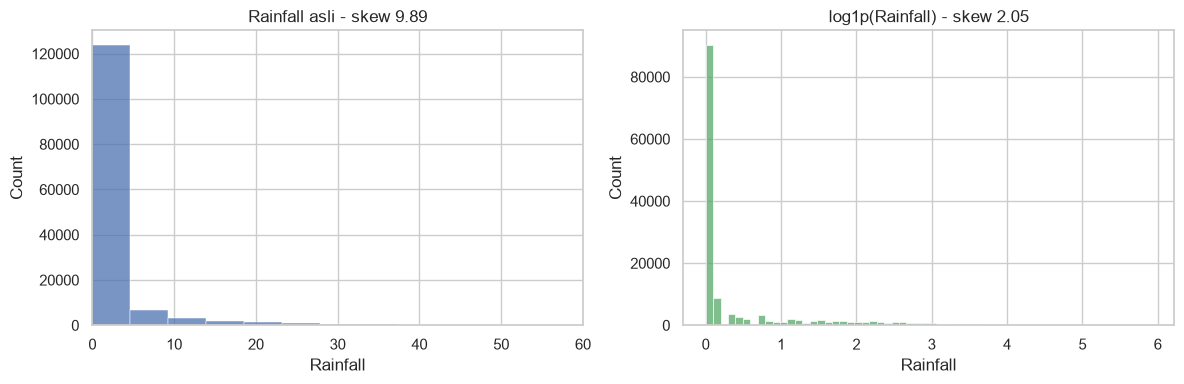

Panel kiri di-zoom ke 0-60 mm; nilai maksimum sebenarnya 371 mm.


In [57]:
# Gambar histogram Rainfall asli dan hasil log1p.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(r, bins=80, ax=axes[0], color="#4C72B0")
axes[0].set_title(f"Rainfall asli - skew {r.skew():.2f}")
axes[0].set_xlim(0, 60)
sns.histplot(np.log1p(r), bins=60, ax=axes[1], color="#55A868")
axes[1].set_title(f"log1p(Rainfall) - skew {np.log1p(r).skew():.2f}")
plt.tight_layout()
plt.show()
print(f"Panel kiri di-zoom ke 0-60 mm; nilai maksimum sebenarnya {r.max():.0f} mm.")

### 8.4 Distribusi Fitur Kunci Lainnya

Tidak semua kolom perlu ditransformasi. Empat fitur penting diperiksa: `Sunshine`, `Humidity3pm`,
`MaxTemp`, `WindGustSpeed`.

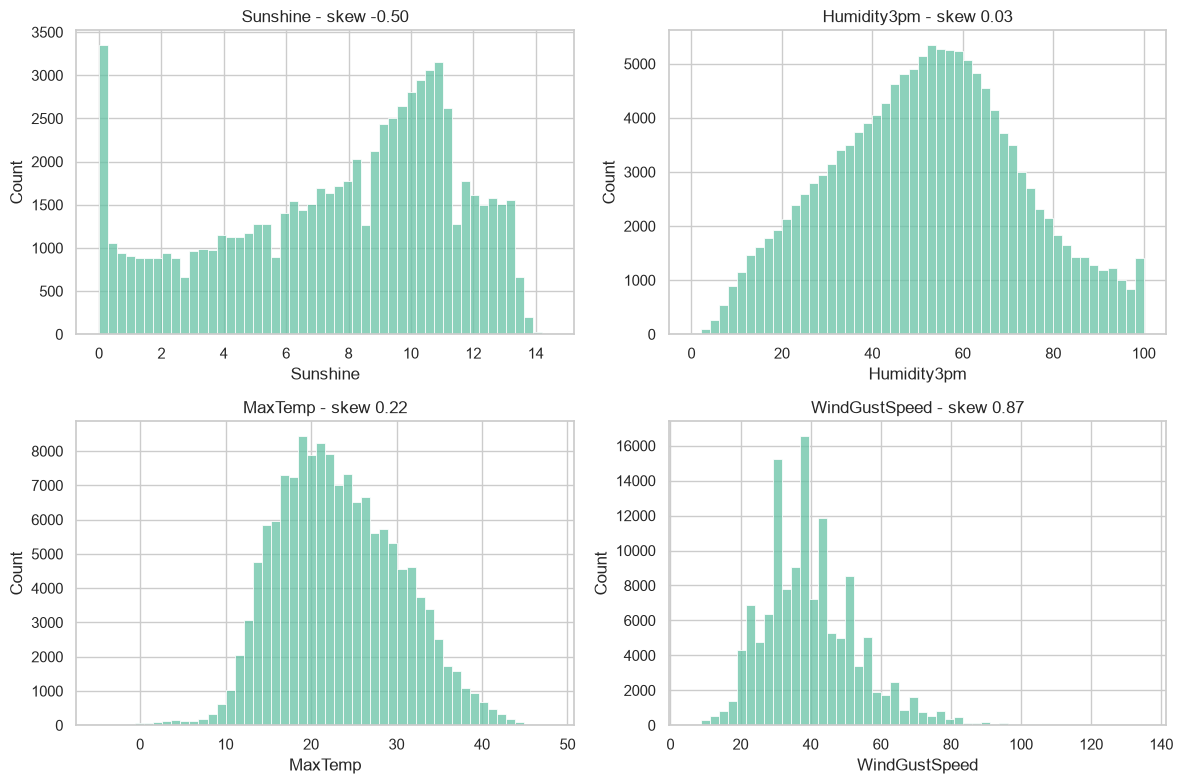

In [58]:
# Gambar distribusi empat fitur kunci.
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), ["Sunshine", "Humidity3pm", "MaxTemp", "WindGustSpeed"]):
    sns.histplot(df[col].dropna(), bins=50, ax=ax)
    ax.set_title(f"{col} - skew {df[col].skew():.2f}")
plt.tight_layout()
plt.show()

### Hasil Histogram Fitur Kunci

- **`Sunshine` bimodal** (puncak ~0-1 jam dan ~10-11 jam) - bukan error, ini dua regime cuaca:
  mendung/hujan vs cerah.
- **`Humidity3pm`** mendekati simetris, menyebar di 10-100%.
- **`MaxTemp`** mendekati normal - tidak perlu transformasi.
- **`WindGustSpeed`** menceng sedang ke kanan - angin kencang jarang, tetapi itu sinyal cuaca ekstrem.

### 8.5 Outlier Statistik != Error Sensor

Boxplot menandai titik di luar 1,5 x IQR sebagai outlier - di data cuaca belum tentu error. Prinsip tim:

- **Mustahil secara fisika** -> sudah di-NaN di Bagian 7.
- **Ekstrem tapi valid** -> dipertahankan (kejadian iklim nyata).
- **Tanpa winsorize/clipping** - memotong ekor = membuang kasus hujan ekstrem yang justru ingin diprediksi.

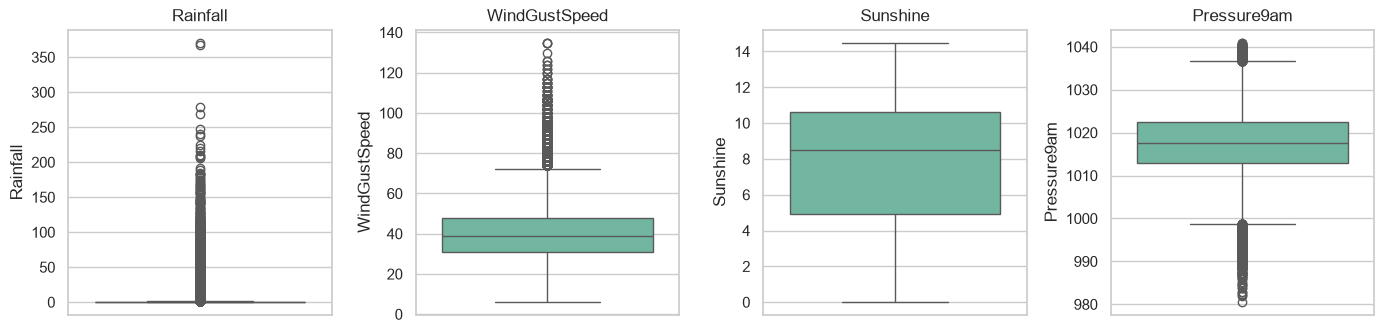

In [59]:
# Lihat outlier statistik memakai boxplot.
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, col in zip(axes, ["Rainfall", "WindGustSpeed", "Sunshine", "Pressure9am"]):
    sns.boxplot(y=df[col].dropna(), ax=ax).set(title=col)
plt.tight_layout()
plt.show()

In [60]:
# Tampilkan kejadian hujan sangat ekstrem yang tetap dipertahankan.
top_rain = df.loc[df["Rainfall"] > 200, ["Date", "Location", "Rainfall"]].sort_values("Rainfall", ascending=False)
display(top_rain)
print(f"Jumlah: {len(top_rain):,} baris | Maks: {top_rain['Rainfall'].max():.0f} mm")
print("Lokasi:", sorted(top_rain["Location"].unique()))

,Date,Location,Rainfall
68084,2009-11-07,CoffsHarbour,371.0
36837,2011-02-16,Darwin,367.6
51779,2009-01-12,Cairns,278.4
62506,2011-02-04,Cairns,268.6
52101,2015-02-08,Cairns,247.2
127041,2015-04-23,Newcastle,240.0
26769,2009-02-03,Townsville,236.8
3240,2016-01-06,Williamtown,225.0
93407,2016-06-05,CoffsHarbour,219.6
3634,2016-01-06,Newcastle,216.3


Jumlah: 14 baris | Maks: 371 mm
Lokasi: ['Cairns', 'CoffsHarbour', 'Darwin', 'Newcastle', 'Townsville', 'Williamtown']


### Hujan Ekstrem

14 baris `Rainfall > 200 mm`, maksimum 371 mm - semuanya di stasiun pesisir basah (Cairns, Darwin,
CoffsHarbour, Townsville, Newcastle, Williamtown).

Ini kejadian iklim nyata (monsun/badai), bukan error sensor -> **dipertahankan**. Skew-nya ditangani
dengan `log1p` di pipeline, bukan dengan memotong data.

### Decision Log Distribusi & Outlier

| Apa | Kenapa | Dampaknya |
|---|---|---|
| `Rainfall` skew 9,9 -> `log1p` di pipeline | 9,9 -> 2,1; membantu model linear, tree tetap invarian | transformasi ikut model, aman untuk aplikasi |
| `Sunshine` bimodal dibiarkan | dua puncak adalah regime cuaca nyata | sinyal prediktif kuat dipertahankan |
| Outlier hujan/angin ekstrem dipertahankan | kejadian iklim nyata | model tetap belajar kasus penting |
| Tanpa winsorize/clipping | memotong ekor membuang kasus yang ingin diprediksi | distribusi asli tetap terjaga |

## 9. Relasi Antar Kolom & Redundansi

> **Tahapan CRISP-DM:** Fase 2 - Data Understanding

Tiga hal diperiksa pada data bersih: korelasi antar kolom numerik, kolom yang paling berhubungan
dengan target, dan **redundansi** (kolom yang isinya hampir sama sehingga membebani model).

### 9.1 Heatmap Korelasi Antar Fitur Numerik

Korelasi Pearson pada data bersih (`Evaporation` sudah dibuang). `RainTomorrow` bertipe `category`
sehingga tidak ikut otomatis di heatmap numerik - korelasinya terhadap target dihitung terpisah di 9.5.

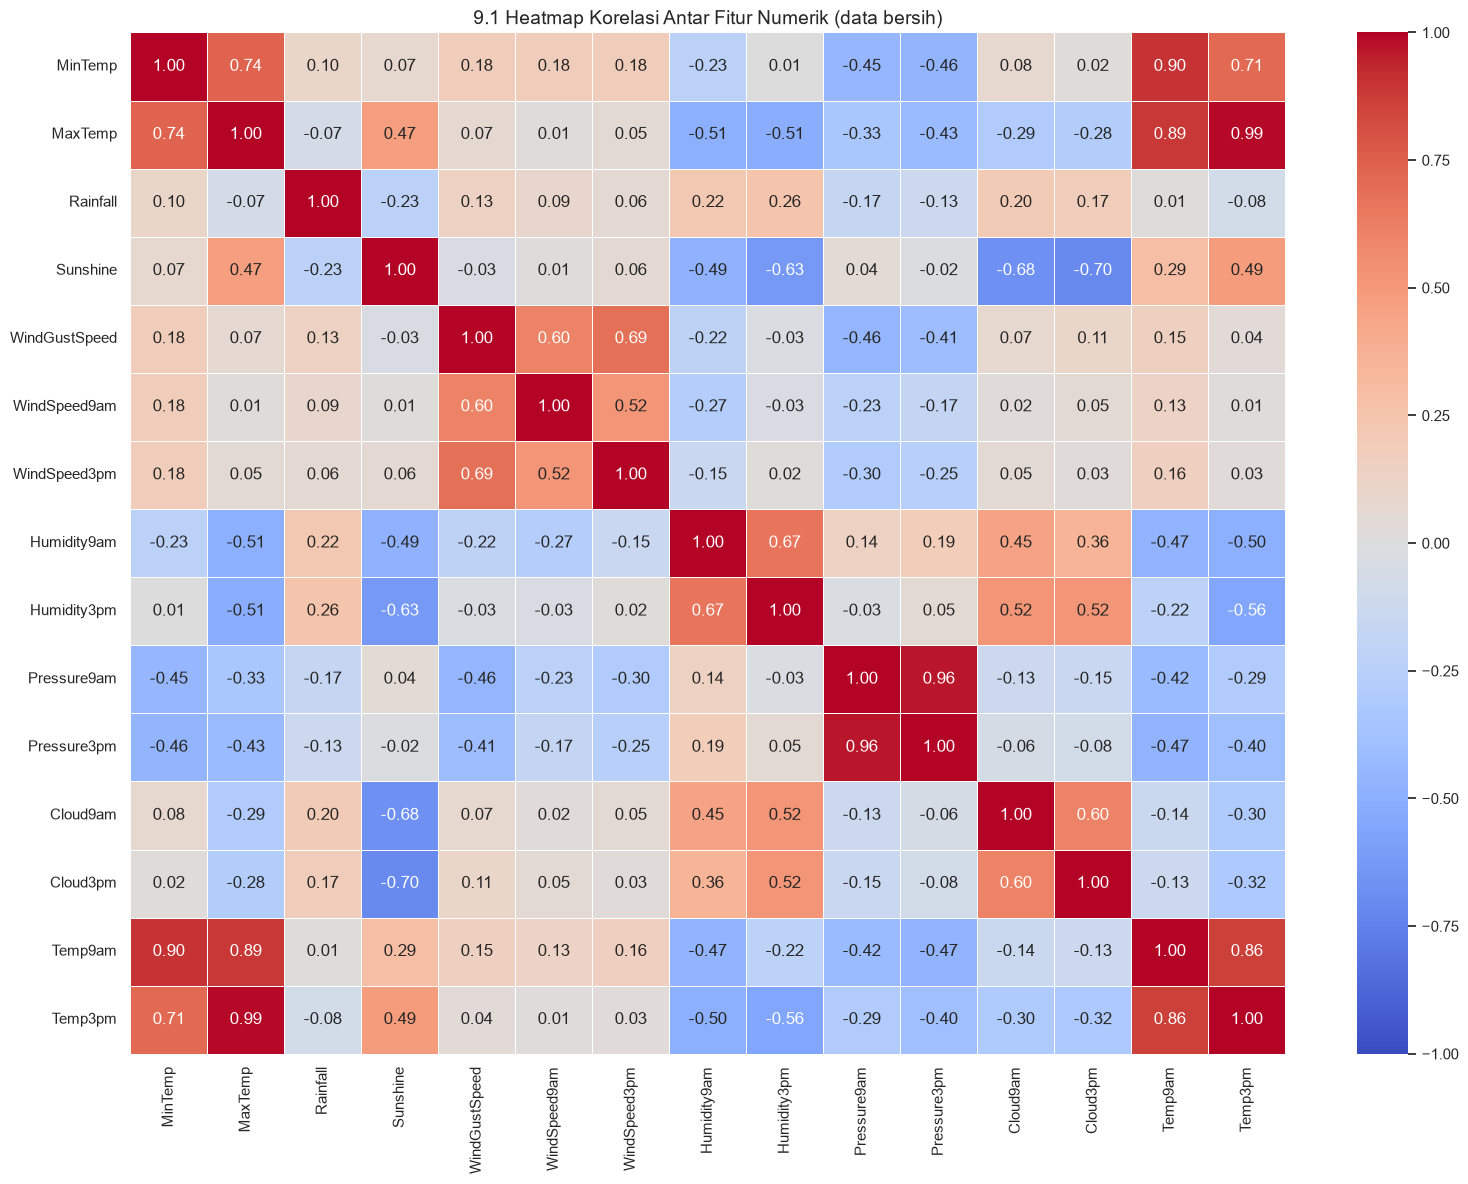

In [61]:
# Hitung dan gambar matriks korelasi antar fitur numerik.
corr_matrix = df[NUM_COLS].corr()

plt.figure(figsize=(16, 12))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("9.1 Heatmap Korelasi Antar Fitur Numerik (data bersih)", fontsize=14)
plt.tight_layout()
plt.show()

### Cara Membaca Heatmap

Merah = positif, biru = negatif, diagonal = 1,00. Makin dekat ke +1/-1 hubungan **linear**-nya makin
kuat. Heatmap tidak menangkap pola non-linear.

### 9.2 Pasangan Fitur yang Sangat Kuat

Difilter pada `\|r\| > 0,85` - ambang penyaring awal untuk diskusi redundansi, bukan hukum mutlak.

In [62]:
# Kumpulkan pasangan kolom lalu saring korelasi sangat kuat.
semua_pair = []
for i, kolom_a in enumerate(NUM_COLS):
    for kolom_b in NUM_COLS[i + 1:]:
        r = corr_matrix.loc[kolom_a, kolom_b]
        semua_pair.append({"kolom_1": kolom_a, "kolom_2": kolom_b, "r": r})

pair_tab = pd.DataFrame(semua_pair)
redundan = pair_tab[pair_tab["r"].abs() > 0.85].sort_values("r", ascending=False)
display(redundan.round(3))

,kolom_1,kolom_2,r
26,MaxTemp,Temp3pm,0.985
90,Pressure9am,Pressure3pm,0.961
12,MinTemp,Temp9am,0.902
25,MaxTemp,Temp9am,0.887
104,Temp9am,Temp3pm,0.863


### Interpretasi Pasangan Positif Sangat Kuat

| Pasangan | r | Interpretasi |
|---|---:|---|
| `MaxTemp` & `Temp3pm` | 0.985 | suhu jam 3 sore hampir selalu dekat suhu maksimum harian |
| `Pressure9am` & `Pressure3pm` | 0.961 | tekanan udara sangat stabil dalam satu hari |
| `MinTemp` & `Temp9am` | 0.902 | suhu pagi dekat suhu minimum harian |
| `MaxTemp` & `Temp9am` | 0.887 | suhu pagi juga terkait suhu maksimum |
| `Temp9am` & `Temp3pm` | 0.863 | pola suhu pagi dan sore mirip |

**Tidak semua harus dihapus.** Tree model toleran terhadap korelasi antar fitur, dan `Temp3pm` punya korelasi target (-0,189) sedikit lebih kuat dari `MaxTemp` (-0,159). Pruning harus diuji lewat cross-validation, bukan asal hapus.

In [63]:
# Tampilkan pasangan fitur yang berkorelasi negatif kuat.
negatif = pair_tab[pair_tab["r"] < -0.5].sort_values("r")
display(negatif.head(10).round(3))

,kolom_1,kolom_2,r
47,Sunshine,Cloud3pm,-0.704
46,Sunshine,Cloud9am,-0.676
43,Sunshine,Humidity3pm,-0.629
89,Humidity3pm,Temp3pm,-0.557
20,MaxTemp,Humidity3pm,-0.509
19,MaxTemp,Humidity9am,-0.505
83,Humidity9am,Temp3pm,-0.501


### Interpretasi Pasangan Negatif Kuat

| Pasangan | r | Interpretasi |
|---|---:|---|
| `Sunshine` & `Cloud3pm` | -0.704 | makin banyak awan sore, makin sedikit sinar matahari |
| `Sunshine` & `Cloud9am` | -0.676 | awan pagi mengurangi durasi sunshine |
| `Sunshine` & `Humidity3pm` | -0.629 | hari cerah cenderung lebih kering |
| `Humidity3pm` & `Temp3pm` | -0.557 | suhu sore naik, kelembapan relatif turun |
| `MaxTemp` & `Humidity3pm` | -0.509 | hari panas cenderung lebih kering |

Semuanya masuk akal secara meteorologi dan **bukan redundansi yang harus dibuang** - justru berguna sebagai quality check dan sinyal cuaca.

In [64]:
# Fokus pada korelasi antar variabel kecepatan angin.
wind_cols = [c for c in NUM_COLS if "Wind" in c]
pasangan_angin = pair_tab[pair_tab["kolom_1"].isin(wind_cols) & pair_tab["kolom_2"].isin(wind_cols)]
display(pasangan_angin.sort_values("r", ascending=False).round(3))

,kolom_1,kolom_2,r
51,WindGustSpeed,WindSpeed3pm,0.686
50,WindGustSpeed,WindSpeed9am,0.605
60,WindSpeed9am,WindSpeed3pm,0.520


### Interpretasi Variabel Angin Numerik

`WindGustSpeed`-`WindSpeed3pm` ~0,686; `WindGustSpeed`-`WindSpeed9am` ~0,605; `WindSpeed9am`-`WindSpeed3pm` ~0,520. Moderat -> ketiganya masih membawa informasi berbeda (angin pagi, sore, hembusan puncak).

Fitur gabungan (`Avg_Wind_Speed`) **ditunda** ke fase modeling: fitur baru masuk hanya jika terbukti menaikkan skor lewat cross-validation.

### 9.3 Redundansi `RainToday` dengan `Rainfall`

`RainToday` secara definisi diturunkan dari `Rainfall > 1 mm`. Dicek apakah labelnya konsisten 100%
dengan aturan tersebut.

In [65]:
# Cek konsistensi RainToday terhadap aturan Rainfall lebih dari satu mm.
ada = df[["RainToday", "Rainfall"]].notna().all(axis=1)
aturan = df["Rainfall"] > 1
label = df["RainToday"] == "Yes"
cocok = ada & (aturan == label)
print(f"Dicek: {int(ada.sum()):,} | Cocok: {int(cocok.sum()):,} | Persentase: {cocok.sum()/ada.sum()*100:.1f}%")

subset = df[ada].copy()
subset["hujan_lebih_1mm"] = subset["Rainfall"] > 1
display(pd.crosstab(subset["hujan_lebih_1mm"], subset["RainToday"]))

Dicek: 140,787 | Cocok: 140,787 | Persentase: 100.0%


RainToday,No,Yes
hujan_lebih_1mm,,
False,109332,0
True,0,31455


### Interpretasi `RainToday`

Kecocokan **100%** pada baris yang keduanya terisi -> `RainToday` fitur turunan `Rainfall`, teknis redundan.

**Tetap dipertahankan:** mudah diinterpretasi, murah untuk tree, tidak leakage (hujan hari ini diketahui saat prediksi), dan menghapusnya tak otomatis membuat model lebih baik. Bukti sinyal kategorikal di 9.6.

### 9.4 Redundansi Arah Angin

Tiga kolom arah angin bersifat kategorikal, jadi korelasi Pearson tidak cocok. Yang diukur adalah
**tingkat kesepakatan label**: seberapa sering dua kolom arah angin bernilai sama.

In [66]:
# Hitung tingkat kesepakatan antar kolom arah angin.
pasangan = [("WindDir3pm", "WindGustDir"), ("WindDir9am", "WindDir3pm"), ("WindDir9am", "WindGustDir")]

for a, b in pasangan:
    ada = df[[a, b]].notna().all(axis=1)
    sama = ada & (df[a] == df[b])
    pct = sama.sum() / ada.sum() * 100
    print(f"{a} == {b}: dicek={int(ada.sum()):,}, sama={int(sama.sum()):,} ({pct:.1f}%)")

WindDir3pm == WindGustDir: dicek=131,911, sama=41,536 (31.5%)
WindDir9am == WindDir3pm: dicek=130,173, sama=23,235 (17.8%)
WindDir9am == WindGustDir: dicek=125,338, sama=28,053 (22.4%)


### Interpretasi Arah Angin

Kesepakatan hanya `WindDir3pm` vs `WindGustDir` 31,5%, `WindDir9am` vs `WindDir3pm` 17,9%, `WindDir9am` vs `WindGustDir` 22,4% -> ketiga kolom **tidak redundan** (arah berubah sepanjang hari; gust bisa beda dari angin rata-rata). Semua dipertahankan.

### 9.5 Korelasi dengan Target `RainTomorrow`

Target bertipe `category` sehingga tidak masuk heatmap numerik. Diubah sementara menjadi `y`
(`Yes` -> 1, `No` -> 0), lalu dihitung korelasi setiap fitur numerik terhadap `y`.

In [67]:
# Ubah target menjadi 1/0 dan hitung korelasi tiap fitur dengan target.
d = df.copy()
d["y"] = (d["RainTomorrow"] == "Yes").astype(int)
target_corr = d.corr(numeric_only=True)["y"].drop("y")
target_corr = target_corr.sort_values(key=abs, ascending=False)
display(target_corr.round(3).to_frame("korelasi_dgn_target"))

,korelasi_dgn_target
Sunshine,-0.451
Humidity3pm,0.446
Cloud3pm,0.382
Cloud9am,0.317
Humidity9am,0.257
Pressure9am,-0.246
Rainfall,0.239
WindGustSpeed,0.234
Pressure3pm,-0.226
Temp3pm,-0.189


### Interpretasi Korelasi Target

| Fitur | r | Arti |
|---|---:|---|
| `Sunshine` | -0.451 | makin cerah hari ini, makin kecil peluang hujan besok |
| `Humidity3pm` | +0.446 | makin lembap sore hari, makin besar peluang hujan besok |
| `Cloud3pm` | +0.382 | makin berawan sore hari, peluang hujan naik |
| `Cloud9am` | +0.317 | awan pagi juga sinyal hujan |
| `Humidity9am` | +0.257 | kelembapan pagi berguna, tetapi lebih lemah |
| `Pressure9am` | -0.246 | tekanan tinggi cenderung cuaca lebih stabil |
| `Rainfall` | +0.239 | hujan hari ini berguna, tetapi tidak menjamin besok hujan |
| `WindGustSpeed` | +0.234 | angin kencang berkaitan dengan sistem cuaca aktif |
| `Temp3pm` | -0.189 | sore lebih panas cenderung lebih kering |
| `MaxTemp` | -0.159 | sinyal suhu maksimum lebih lemah dari `Temp3pm` |

Korelasi linear tunggal tidak cukup (hujan bersifat non-linear), tapi sinyal `Sunshine`, `Humidity3pm`, dan `Cloud*` jelas kuat dan wajib dipertahankan.

### 9.6 Tingkat `RainTomorrow` per Kategori

Korelasi Pearson tak menangkap fitur kategorikal, jadi dihitung **%Yes per kategori** vs **baseline 22,4%**. **Lift** = `%Yes` / baseline (1,00 = rata-rata; 2,00 = dua kali lebih mungkin hujan).

In [68]:
# Tingkat RainTomorrow = Yes per kategori, dibandingkan baseline seluruh data.
d9 = df.assign(y=(df["RainTomorrow"] == "Yes").astype(int),
               Season=df["Date"].dt.month.map(lambda m: (m % 12) // 3))
baseline = d9["y"].mean() * 100

# rate_by: jumlah baris (n), %Yes, dan lift terhadap baseline untuk satu kolom kategorikal.
def rate_by(col, top=None, asc=False):
    g = d9.groupby(col, observed=True)["y"].agg(n="size", rate_yes=lambda s: s.mean() * 100)
    g["lift"] = g["rate_yes"] / baseline
    g = g.sort_values("rate_yes", ascending=asc)
    return (g.head(top) if top else g).round(2)

print(f"Baseline %Yes = {baseline:.1f}%  |  lift 1.00 = sama dengan rata-rata")
print(f"n terkecil per Location = {int(d9.groupby('Location', observed=True).size().min()):,} baris\n")

for col in ["RainToday", "Season", "WindGustDir"]:
    print(f"--- {col} ---")
    display(rate_by(col))

print("--- Location: 8 tertinggi ---")
display(rate_by("Location", top=8))
print("--- Location: 8 terendah ---")
display(rate_by("Location", top=8, asc=True))

Baseline %Yes = 22.4%  |  lift 1.00 = sama dengan rata-rata
n terkecil per Location = 1,521 baris

--- RainToday ---


,n,rate_yes,lift
RainToday,,,
Yes,31455,46.41,2.07
No,109332,15.19,0.68


--- Season ---


,n,rate_yes,lift
Season,,,
2,35930,26.12,1.17
1,37397,21.89,0.98
3,34610,21.24,0.95
0,34256,20.30,0.91


--- WindGustDir ---


,n,rate_yes,lift
WindGustDir,,,
NW,8003,28.54,1.27
NNW,6561,28.40,1.27
WNW,8066,28.20,1.26
N,9033,27.14,1.21
W,9780,26.66,1.19
WSW,8901,23.42,1.04
NNE,6433,23.02,1.03
S,8949,22.54,1.01
SSW,8610,22.03,0.98


--- Location: 8 tertinggi ---


,n,rate_yes,lift
Location,,,
Portland,2996,36.55,1.63
Walpole,2819,33.66,1.50
Cairns,2988,31.79,1.42
Dartmoor,2943,31.33,1.40
NorfolkIsland,2964,31.01,1.38
MountGambier,3030,30.36,1.35
Albany,3016,29.91,1.33
Witchcliffe,2952,29.78,1.33


--- Location: 8 terendah ---


,n,rate_yes,lift
Location,,,
Woomera,2990,6.76,0.30
Uluru,1521,7.63,0.34
AliceSprings,3031,8.05,0.36
Mildura,3007,10.87,0.49
Cobar,2988,12.92,0.58
Moree,2854,13.81,0.62
Nhil,1569,15.42,0.69
SalmonGums,2955,15.97,0.71


### Interpretasi Tingkat Hujan per Kategori

- **`RainToday` = sinyal kategorikal terkuat:** `Yes` 46,4% (lift **2,07**) vs `No` 15,2% (lift 0,68) - hujan hari ini **menggandakan** peluang hujan besok. Bukti `RainToday` layak dipertahankan meski redundan dengan `Rainfall` (9.3).
- **`Location` menyebar 6,8%-36,6%** (Portland tertinggi, Woomera terendah; rasio ~5,4x). Basah = pesisir selatan (Portland, Walpole, Albany, MountGambier) + tropis utara (Cairns, NorfolkIsland); kering = pedalaman (Woomera, Uluru, AliceSprings). `Location` **bukan kolom dekoratif** -> dasar mempertahankannya walau menambah 49 kolom one-hot.
- **`WindGustDir`:** barat/utara-barat (`NW`, `NNW`, `WNW`, `N`, `W`) 26-28% = pembawa front; timur (`E`, `ENE`, `ESE`) 15-16% = aliran kering pedalaman.
- **`Season`:** musim dingin (`Season 2`, Jun-Agu) tertinggi 26,1% vs Des-Feb 20,3% - konsisten dengan stasiun selatan yang lebih basah di musim dingin.

`n` terkecil per kategori 1.521 baris -> perbedaan lift di atas **bukan noise**.

### Decision Log Redundansi

| Apa | Kenapa | Dampaknya |
|---|---|---|
| Pasangan `\|r\| > 0,85` dicatat, tidak langsung dihapus | tree model toleran; `Temp3pm` masih punya sinyal target | tidak kehilangan informasi prematur |
| `RainToday` dipertahankan | 100% turunan `Rainfall > 1`, interpretable, tidak leakage; lift 2,07 (9.6) | fitur tetap murah dan mudah dijelaskan |
| `Location` dipertahankan | %Yes antar stasiun menyebar 6,8%-36,6% (9.6) -> membawa informasi iklim | 49 kolom one-hot dibayar dengan sinyal nyata |
| Arah angin dipertahankan | kesepakatan label hanya 18-32% | ketiga kolom membawa informasi berbeda |
| Feature selection final ditunda ke modeling | keputusan harus diuji cross-validation | menghindari spekulasi |

## 10. Data Siap Pakai

> **Tahapan CRISP-DM:** Fase 3 - Data Preparation

Snapshot `df` setelah transformasi tipe data, drop `Evaporation`, drop baris tanpa `RainTomorrow`,
dan koreksi nilai tidak valid menjadi NaN. Data inilah yang masuk ke Bagian 11 lalu ke fase modeling.

In [69]:
# Tampilkan bentuk dan memori data siap pakai.
print(f"Bentuk akhir   : {len(df):,} baris x {df.shape[1]} kolom")
print(f"Memori         : {df.memory_usage(deep=True).sum()/1e6:.1f} MB")
print(f"Target         : {dict(df['RainTomorrow'].value_counts())}")
print("Kolom dibuang  : Evaporation")

Bentuk akhir   : 142,193 baris x 22 kolom
Memori         : 24.4 MB
Target         : {'No': np.int64(110316), 'Yes': np.int64(31877)}
Kolom dibuang  : Evaporation


In [70]:
# Tampilkan kolom yang masih memiliki NaN.
total_nan = int(df.isna().sum().sum())
print(f"Total sel NaN: {total_nan:,} ({total_nan/df.size*100:.1f}%)")

nan_sisa = df.isna().sum()
display(nan_sisa[nan_sisa > 0].sort_values(ascending=False).to_frame("n_nan"))

Total sel NaN: 256,263 (8.2%)


,n_nan
Sunshine,67816
Cloud3pm,57094
Cloud9am,53657
Pressure9am,14014
Pressure3pm,13981
WindDir9am,10013
WindGustDir,9330
WindGustSpeed,9275
WindDir3pm,3778
Humidity3pm,3610


### Snapshot Data Siap Pakai

- **142.193 baris x 22 kolom** = `Date` + 15 numerik + 5 kategorikal fitur + `RainTomorrow`.
- NaN sengaja dibiarkan karena bersifat struktural atau hasil koreksi validitas.
- XGBoost memakai NaN native; RandomForest/LogisticRegression memakai imputasi **di dalam pipeline**,
  bukan di dataframe global.

## 11. Data Preparation & Split

> **Tahapan CRISP-DM:** Fase 3 - Data Preparation

Menutup checklist item 10-15: feature engineering, encoding, normalisasi/standardisasi, feature selection, imbalance, dan split.

**Anti-leakage:** semua transformasi yang belajar dari data (imputer, scaler, encoder) hanya di-fit pada train -> dipasang di `sklearn.Pipeline` saat modeling, bukan pada dataframe global di notebook ini.

### 11.1 Feature Engineering - `Month` & `Season`

`Date` hampir selalu unik, jadi tak dipakai langsung - yang berguna pola musimannya:

- `Month` = bulan 1-12.
- `Season` = 0 (Des-Feb), 1 (Mar-Mei), 2 (Jun-Agu), 3 (Sep-Nov).

`Year` **sengaja tidak dipakai** - data berakhir 2017, tren tahun tak terulang di produksi.

In [71]:
# Buat fitur musiman dari tanggal: Month dan Season.
df_prep = df.copy()
df_prep["Month"] = df_prep["Date"].dt.month
df_prep["Season"] = df_prep["Month"].map(lambda m: (m % 12) // 3)
print(f"Kolom: {df.shape[1]} -> {df_prep.shape[1]} (+Month, +Season)")

Kolom: 22 -> 24 (+Month, +Season)


In [72]:
# Cek hasil feature engineering musiman pada beberapa baris.
display(df_prep[["Date", "Month", "Season"]].head())
print(df_prep["Season"].value_counts().sort_index())

,Date,Month,Season
0,2008-12-16,12,0
1,2010-02-10,2,0
2,2010-02-12,2,0
6,2013-06-05,6,2
9,2009-10-05,10,3


Season
0    34256
1    37397
2    35930
3    34610
Name: count, dtype: int64


In [73]:
# Hitung peluang hujan besok untuk setiap bulan.
df_prep["y"] = (df_prep["RainTomorrow"] == "Yes").astype(int)
rate_bulan = df_prep.groupby("Month")["y"].mean() * 100
print(rate_bulan.round(1).to_string())

Month
1     19.3
2     21.0
3     21.3
4     21.8
5     22.5
6     26.2
7     26.9
8     25.3
9     23.0
10    19.6
11    21.3
12    20.8


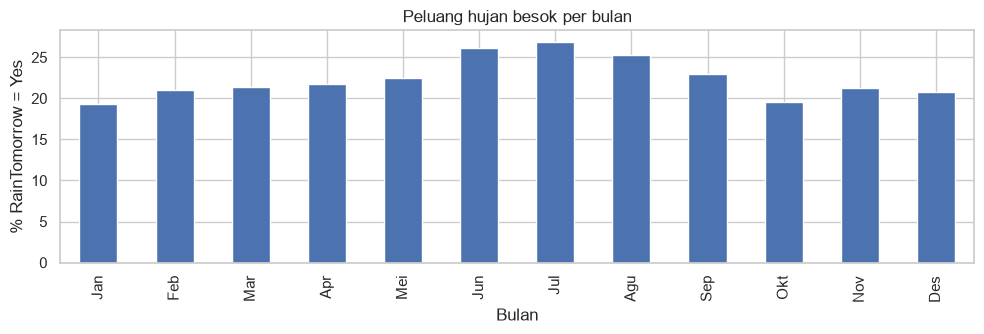

In [74]:
# Visualisasikan peluang hujan per bulan.
fig, ax = plt.subplots(figsize=(10, 3.5))
rate_bulan.plot(kind="bar", ax=ax, color="#4C72B0")
ax.set_xlabel("Bulan")
ax.set_ylabel("% RainTomorrow = Yes")
ax.set_title("Peluang hujan besok per bulan")
ax.set_xticks(range(12))
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"])
plt.tight_layout()
plt.show()

### Bukti Musiman

Batang naik-turun -> ada pola musiman. Di Australia pola hujan beda per wilayah: musim dingin lebih basah di selatan, monsun Nov-Mar kuat di utara -> `Month` & `Season` dipertahankan.

Ide lain (`Avg_Wind_Speed`, selisih tekanan, rasio kelembapan pagi-sore) **ditunda** ke modeling: fitur baru masuk hanya jika terbukti membantu lewat cross-validation.

### 11.2 Encoding - OneHot, bukan Label

Lima fitur kategorikal final: `Location`, `WindGustDir`, `WindDir9am`, `WindDir3pm`, `RainToday`.
Semuanya **nominal** (tanpa urutan matematis) -> `OneHotEncoder` membuat satu kolom biner per kategori.

Target `RainTomorrow` dipetakan manual: `Yes` -> 1, `No` -> 0.

In [75]:
# Definisikan fitur kategorikal dan hitung jumlah kategori tiap kolom.
CAT_FEATS = ["Location", "WindGustDir", "WindDir9am", "WindDir3pm", "RainToday"]
jumlah_kategori = df_prep[CAT_FEATS].nunique().rename("jumlah_kategori")
display(jumlah_kategori.to_frame())

,jumlah_kategori
Location,49
WindGustDir,16
WindDir9am,16
WindDir3pm,16
RainToday,2


In [76]:
# Hitung jumlah kolom model sebelum dan sesudah one-hot encoding.
total_onehot = int(jumlah_kategori.sum())
num_after_fe = len(NUM_COLS) + 2

print(f"Kolom kategori sebelum one-hot : {len(CAT_FEATS)}")
print(f"Total kolom hasil one-hot      : {total_onehot}")
print(f"Kolom numerik setelah FE       : {num_after_fe}")
print(f"Total fitur model              : {total_onehot + num_after_fe}")

Kolom kategori sebelum one-hot : 5
Total kolom hasil one-hot      : 99
Kolom numerik setelah FE       : 17
Total fitur model              : 116


### Hasil Encoding

99 kolom one-hot (49 + 16 + 16 + 16 + 2) + 17 numerik (15 + `Month` + `Season`) = **116 fitur**
sebelum masuk model.

One-hot dilakukan **di dalam pipeline**, bukan manual di notebook, agar kategori yang dipelajari hanya
berasal dari data train.

### 11.3 Normalisasi & Standardisasi

| Model | Butuh scaling? | Alasan |
|---|---|---|
| LogisticRegression | Ya | koefisien dan konvergensi sensitif terhadap skala |
| RandomForest / XGBoost | Tidak | split pohon hanya memakai urutan nilai |

**Keputusan:** `StandardScaler` dipasang seragam di pipeline (wajib untuk LR, tak merusak tree); `log1p(Rainfall)` juga jadi step pipeline.

**Titik kritis leakage:** mean & std hanya boleh dari `X_train`. Bila dari seluruh data, informasi test bocor ke training dan metrik terlalu optimis.

In [77]:
# Contoh mean dan std yang nanti dipelajari StandardScaler di pipeline.
contoh = df_prep[["Rainfall", "Humidity3pm", "Pressure3pm"]].describe().loc[["mean", "std"]]
display(contoh.round(2))
print("Dua angka per kolom (mean & std) inilah yang nanti dipelajari StandardScaler.")
print("Di fase modeling: fit hanya pada X_train, lalu transform X_test.")
print("Angka di atas dihitung dari seluruh data HANYA untuk ilustrasi.")

,Rainfall,Humidity3pm,Pressure3pm
mean,2.35,51.48,1015.26
std,8.47,20.80,7.04


Dua angka per kolom (mean & std) inilah yang nanti dipelajari StandardScaler.
Di fase modeling: fit hanya pada X_train, lalu transform X_test.
Angka di atas dihitung dari seluruh data HANYA untuk ilustrasi.


### 11.4 Feature Selection

| Aksi | Kolom | Alasan |
|---|---|---|
| Diekstrak lalu tidak dipakai langsung | `Date` | sudah menjadi `Month` / `Season` |
| Tidak dipakai | `Year` | risiko ekstrapolasi tren masa depan |
| Drop | `Evaporation` | missing 43%, sinyal terlemah |
| Jadi label | `RainTomorrow` | target -> `y` |
| Pertahankan | 22 fitur | 17 numerik + 5 kategorikal |

Multikolinearitas tidak dihapus sekarang - pruning ditunda ke fase modeling dan harus diuji lewat cross-validation.

In [78]:
# Definisikan daftar fitur final sebelum encoding.
NUM_FEATS = NUM_COLS + ["Month", "Season"]
CAT_FEATS = ["Location", "WindGustDir", "WindDir9am", "WindDir3pm", "RainToday"]
FEATURES = NUM_FEATS + CAT_FEATS

print(f"{len(NUM_FEATS)} numerik : {NUM_FEATS}")
print(f"{len(CAT_FEATS)} kategori : {CAT_FEATS}")
print(f"Total {len(FEATURES)} fitur sebelum one-hot")

17 numerik : ['MinTemp', 'MaxTemp', 'Rainfall', 'Sunshine', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm', 'Month', 'Season']
5 kategori : ['Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday']
Total 22 fitur sebelum one-hot


### 11.5 Class Imbalance

Imbalance: ~77,6% `No` / ~22,4% `Yes`. Keputusan tim:

- Metrik utama **F1**, didukung PR-AUC & ROC-AUC.
- **Class weight**, bukan SMOTE: LR/RF `class_weight="balanced"`, XGBoost `scale_pos_weight = negatif / positif`.
- SMOTE ditolak: sampel sintetis pada data deret waktu berisiko melintasi batas split & merusak pola musiman.
- Threshold default 0,5.

> PR-AUC dan **threshold optimal** dihitung di **Bagian 12**; uji empiris SMOTE vs class weight di luar cakupan notebook ini (keputusan: class weight).

In [79]:
# Hitung proporsi kelas dan scale_pos_weight untuk XGBoost.
pos = int(df_prep["y"].sum())
neg = int((df_prep["y"] == 0).sum())

print(f"Yes = {pos:,} ({pos/(pos+neg)*100:.1f}%)")
print(f"No  = {neg:,} ({neg/(pos+neg)*100:.1f}%)")
print(f"scale_pos_weight (XGBoost) = {neg/pos:.2f}")
print(f"Baseline 'selalu jawab No' = akurasi {neg/(pos+neg)*100:.1f}%")

Yes = 31,877 (22.4%)
No  = 110,316 (77.6%)
scale_pos_weight (XGBoost) = 3.46
Baseline 'selalu jawab No' = akurasi 77.6%


### 11.6 Data Split - Time-Based 80/20

Split kronologis tanpa shuffle: 80% paling awal = train, 20% paling akhir = test - mencegah model belajar dari masa depan (anti-leakage temporal). Hasil konkretnya dibahas setelah output di bawah.

In [80]:
# Urutkan data menurut waktu lalu split 80 persen train dan 20 persen test.
df_prep = df_prep.sort_values("Date").reset_index(drop=True)
split_idx = int(len(df_prep) * 0.8)
train = df_prep.iloc[:split_idx]
test = df_prep.iloc[split_idx:]

print(f"Train : {len(train):,} baris | {train['Date'].min().date()} s.d. {train['Date'].max().date()}")
print(f"Test  : {len(test):,} baris | {test['Date'].min().date()} s.d. {test['Date'].max().date()}")

Train : 113,754 baris | 2007-11-01 s.d. 2015-11-10
Test  : 28,439 baris | 2015-11-10 s.d. 2017-06-25


In [81]:
# Pastikan tidak ada tanggal train yang melewati batas test.
assert train["Date"].max() <= test["Date"].min(), "LEAK: ada tanggal train melewati batas test!"
print("Tidak ada tanggal train yang melewati batas test.")

if train["Date"].max() == test["Date"].min():
    print("Tanggal batas sama karena beberapa stasiun pada hari itu terpotong dua.")
    print("Ini bukan kebocoran informasi lintas waktu.")

Tidak ada tanggal train yang melewati batas test.
Tanggal batas sama karena beberapa stasiun pada hari itu terpotong dua.
Ini bukan kebocoran informasi lintas waktu.


In [82]:
# Bandingkan proporsi target pada train dan test.
print(f"Train %Yes = {train['y'].mean()*100:.1f}")
print(f"Test  %Yes = {test['y'].mean()*100:.1f}")

selisih = abs(train["y"].mean() - test["y"].mean()) * 100
print(f"Selisih = {selisih:.1f} poin persen")

Train %Yes = 22.4
Test  %Yes = 22.3
Selisih = 0.1 poin persen


### Hasil Split

- Train lebih dulu, test lebih akhir; tak ada tanggal train melewati batas test.
- `%Yes` train 22,4 vs test 22,3 -> split sehat (proporsi mirip = perbandingan model tidak bias karena split).
- Batas **2015-11-10** sama di kedua sisi karena beberapa stasiun hari itu terpotong dua - **bukan** leakage temporal (tiap baris stasiun berbeda).

**Fase modeling:** fit pipeline hanya pada `X_train` -> cross-validation & tuning -> bandingkan LR/RF/XGBoost -> sentuh `X_test` sekali di akhir untuk evaluasi final.

## 12. Modeling & Evaluasi

> **CRISP-DM:** Fase 4-5 - Modeling & Evaluation

Justifikasi model selection 3 langkah, semua di atas pipeline anti-leakage (imputer + scaler + one-hot di-fit hanya pada `train`) dengan **class weight** (keputusan 11.5):

1. **12.1 Benchmark awal** - LogisticRegression / RandomForest / XGBoost dengan param awal proyek, semua dilatih penuh -> pemenang *sementara*.
2. **12.2 Tuning hyperparameter SEMUA model** - protokol identik (TimeSeriesSplit, scoring F1, threshold dari OOF train) -> tidak ada model yang diuntungkan/dikorbankan.
3. **12.3 Benchmark tuned & seleksi final** - evaluasi sekali di test; pemenang dikonfirmasi (atau dikoreksi) dengan bukti. **12.4** membedah model final: confusion matrix pada threshold optimal + feature importance.


### 12.1 Benchmark Awal (Param Awal Proyek)

Latih 3 model dengan param awal yang sama-sama "diberi makan penuh": LR (liblinear + class weight), RF 300 tree (`balanced_subsample`), XGB 400 tree / lr 0.08 (`scale_pos_weight`). Preprocessing identik untuk semua model. Boosting yang dipangkas (mis. XGB 100 tree / lr rendah) akan kalah tidak adil - boosting butuh banyak ronde.


In [83]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from xgboost import XGBClassifier

# 1. Hitung bobot kelas untuk mengatasi imbalance secara dinamis dari data train
# Train target: train['y']
y_train = train['y']
y_test = test['y']

neg_count = int((y_train == 0).sum())
pos_count = int((y_train == 1).sum())
total_count = len(y_train)

# class_weights: {0: weight_for_No, 1: weight_for_Yes}
class_weights = {
    0: total_count / (2 * neg_count),
    1: total_count / (2 * pos_count)
}

# 2. Siapkan fitur-fitur dan pipeline preprocessing
# Kita pisahkan kolom numerik dan kategorikal
num_cols = [c for c in FEATURES if c not in CAT_FEATS]

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ]), CAT_FEATS)
])

# Transformasi data fitur
X_train_processed = preprocessor.fit_transform(train[FEATURES])
X_test_processed = preprocessor.transform(test[FEATURES])

# 3. Definisikan model menggunakan class_weights dan parameter pendukung yang telah dihitung
models = {
    "LogisticRegression": LogisticRegression(
        max_iter=2000,
        solver="liblinear",
        class_weight=class_weights,
        random_state=42,
    ),
    "RandomForest": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=5,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1,
    ),
    "XGBoost": XGBClassifier(
        n_estimators=400,
        max_depth=6,
        learning_rate=0.08,
        subsample=0.9,
        colsample_bytree=0.9,
        scale_pos_weight=neg_count / pos_count,
        random_state=42,
        n_jobs=-1,
        eval_metric="logloss",
    ),
}

trained_models = {}
results = []

for name, model in models.items():
    # Fit model tanpa sample_weight_train agar lebih sederhana dan konsisten
    trained = model.fit(X_train_processed, y_train.to_numpy())
    trained_models[name] = trained
    y_pred = trained.predict(X_test_processed)
    y_prob = trained.predict_proba(X_test_processed)[:, 1]

    metrics = {
        "model": name,
        "accuracy": accuracy_score(y_test.to_numpy(), y_pred),
        "precision": precision_score(y_test.to_numpy(), y_pred, zero_division=0),
        "recall": recall_score(y_test.to_numpy(), y_pred, zero_division=0),
        "f1": f1_score(y_test.to_numpy(), y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test.to_numpy(), y_prob),
        "pr_auc": average_precision_score(y_test.to_numpy(), y_prob),
    }
    results.append(metrics)

model_summary = pd.DataFrame(results).sort_values(["f1", "pr_auc", "roc_auc"], ascending=False).reset_index(drop=True)
display(model_summary.round(3))

best_model_name = model_summary.iloc[0]["model"]
best_model = trained_models[best_model_name]
print(f"\nModel terbaik: {best_model_name}")
print(f"Baris train: {X_train_processed.shape[0]:,} | Baris test: {X_test_processed.shape[0]:,}")
print(f"Dimensi input model: {X_train_processed.shape}")

,model,accuracy,precision,recall,f1,roc_auc,pr_auc
0,XGBoost,0.819,0.571,0.773,0.657,0.885,0.736
1,RandomForest,0.832,0.614,0.673,0.642,0.873,0.704
2,LogisticRegression,0.796,0.531,0.730,0.614,0.858,0.679



Model terbaik: XGBoost
Baris train: 113,754 | Baris test: 28,439
Dimensi input model: (113754, 116)


### Hasil Benchmark Awal - Pemenang Sementara

- **XGBoost menang F1, PR-AUC, dan ROC-AUC** -> pemenang *sementara*; RF hanya unggul akurasi - justru metrik yang menyesatkan (baseline selalu-`No` = 77,6%).
- Catatan penting: perbandingan hanya adil bila semua model dilatih penuh. XGBoost yang dipangkas (mis. 100 tree) akan tampak kalah dari RandomForest karena boosting butuh banyak ronde - jebakan yang perlu dihindari.
- **Ini belum keputusan final.** Param awal belum tentu optimal untuk masing-masing model - apakah ranking bertahan setelah semuanya di-tuning? Dijawab di 12.2-12.3.


### 12.2 Tuning Hyperparameter - Semua Model, Protokol Identik


In [90]:
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV, TimeSeriesSplit
from sklearn.base import clone
import time

# Versi RINGAN — protokol tetap identik (keputusan 11.5):
# - TimeSeriesSplit(3), scoring F1, tanpa SMOTE, class weight dikunci
# - Threshold tetap dari proba OOF di TRAIN PENUH
# - Yang diubah: ukuran search space + kompleksitas kandidat saja

X_tr = np.asarray(X_train_processed)
y_tr = y_train.to_numpy()
tscv = TimeSeriesSplit(n_splits=3)

# (Opsional) tuning di potongan terbaru saja kalau train sangat besar.
# urutan waktu tetap terjaga karena ambil baris paling belakang.
MAX_TUNING_ROWS = 40_000
if len(y_tr) > MAX_TUNING_ROWS:
    X_tune, y_tune = X_tr[-MAX_TUNING_ROWS:], y_tr[-MAX_TUNING_ROWS:]
else:
    X_tune, y_tune = X_tr, y_tr
print(f"Baris tuning: {len(y_tune):,} | baris train penuh: {len(y_tr):,}")

base_models = {
    "LogisticRegression": LogisticRegression(
        solver="liblinear", max_iter=2000,
        class_weight=class_weights, random_state=42,
    ),
    "RandomForest": RandomForestClassifier(
        class_weight="balanced_subsample", random_state=42, n_jobs=-1,
    ),
    "XGBoost": XGBClassifier(
        scale_pos_weight=neg_count / pos_count, tree_method="hist",
        eval_metric="logloss", random_state=42, n_jobs=-1,
    ),
}

search_spaces = {
    "LogisticRegression": ("grid", {"C": np.logspace(-3, 3, 7)}, None),
    "RandomForest": ("random", {
        "n_estimators": [200, 300],
        "max_depth": [12, 18, 24],
        "min_samples_leaf": [2, 5, 10],
        "min_samples_split": [2, 5, 10],
        "max_features": ["sqrt", 0.5],
    }, 12),
    "XGBoost": ("random", {
        "n_estimators": [300, 500],
        "max_depth": [4, 6, 8],
        "learning_rate": [0.05, 0.10],
        "min_child_weight": [1, 5],
        "subsample": [0.8, 1.0],
        "colsample_bytree": [0.8, 1.0],
        "gamma": [0.0, 0.1, 0.3],
    }, 15),
}

thresholds = np.round(np.arange(0.30, 0.605, 0.01), 2)
tuned_models = {}

for name in ["LogisticRegression", "RandomForest", "XGBoost"]:
    kind, space, n_iter = search_spaces[name]
    t0 = time.time()
    if kind == "grid":
        search = GridSearchCV(base_models[name], space, scoring="f1",
                              cv=tscv, refit=False, n_jobs=-1)
    else:
        search = RandomizedSearchCV(
            base_models[name], space, n_iter=n_iter, scoring="f1",
            cv=tscv, random_state=42, n_jobs=1, refit=False, verbose=1,
        )
    search.fit(X_tune, y_tune)

    best_est = clone(base_models[name]).set_params(**search.best_params_).fit(X_tr, y_tr)
    elapsed = time.time() - t0

    oof = np.full(len(y_tr), np.nan)
    for tr_idx, va_idx in tscv.split(X_tr):
        m = clone(best_est).fit(X_tr[tr_idx], y_tr[tr_idx])
        oof[va_idx] = m.predict_proba(X_tr[va_idx])[:, 1]
    mask = ~np.isnan(oof)
    f1_oof = [f1_score(y_tr[mask], (oof[mask] >= t).astype(int), zero_division=0)
              for t in thresholds]
    best_t = float(thresholds[int(np.argmax(f1_oof))])

    tuned_models[name] = {
        "model": best_est,
        "params": search.best_params_,
        "cv_f1": float(search.best_score_),
        "cv_f1_std": float(search.cv_results_["std_test_score"][search.best_index_]),
        "threshold": best_t,
        "tuning_rows": len(y_tune),
        "time_s": elapsed,
    }
    print("=" * 60)
    print(f"{name}: selesai dalam {elapsed/60:.1f} menit")
    print(f"Best params : {search.best_params_}")
    print(f"CV F1       : {search.best_score_:.4f} +- {tuned_models[name]['cv_f1_std']:.4f}")
    print(f"Threshold optimal (OOF train): {best_t:.2f} | F1 OOF: {max(f1_oof):.4f}")

tuning_summary = pd.DataFrame([
    {"model": n, "cv_f1": i["cv_f1"], "cv_f1_std": i["cv_f1_std"],
     "threshold_oof": i["threshold"], "tuning_rows": i["tuning_rows"],
     "waktu_menit": i["time_s"] / 60}
    for n, i in tuned_models.items()
])
print("=" * 60)
display(tuning_summary.round(4))

Baris tuning: 40,000 | baris train penuh: 113,754
LogisticRegression: selesai dalam 0.1 menit
Best params : {'C': np.float64(1.0)}
CV F1       : 0.6144 +- 0.0221
Threshold optimal (OOF train): 0.60 | F1 OOF: 0.6409
Fitting 3 folds for each of 12 candidates, totalling 36 fits
RandomForest: selesai dalam 1.7 menit
Best params : {'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 10, 'max_features': 0.5, 'max_depth': 18}
CV F1       : 0.6079 +- 0.0242
Threshold optimal (OOF train): 0.49 | F1 OOF: 0.6468
Fitting 3 folds for each of 15 candidates, totalling 45 fits
XGBoost: selesai dalam 0.5 menit
Best params : {'subsample': 0.8, 'n_estimators': 500, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.1, 'gamma': 0.1, 'colsample_bytree': 1.0}
CV F1       : 0.6285 +- 0.0245
Threshold optimal (OOF train): 0.60 | F1 OOF: 0.6635


,model,cv_f1,cv_f1_std,threshold_oof,tuning_rows,waktu_menit
0,LogisticRegression,0.6144,0.0221,0.60,40000,0.0941
1,RandomForest,0.6079,0.0242,0.49,40000,1.6594
2,XGBoost,0.6285,0.0245,0.60,40000,0.5369


### 12.3 Benchmark Tuned & Seleksi Final

Ketiga model tuned dievaluasi **sekali di test** pada threshold optimal masing-masing (baris `@ 0.50` sebagai pembanding). Seleksi: **F1 tertinggi**, tie-break PR-AUC lalu ROC-AUC (konsisten 11.5). Tabel delta menunjukkan seberapa besar tuning benar-benar membantu. Sel ini juga menyimpan `model_comparison.csv` + `best_model_rain_aus.pkl` (model + threshold + preprocessor) ke folder kerja.


In [91]:
import pickle
from pathlib import Path

# Benchmark tuned: semua model dievaluasi SEKALI di test
y_te = y_test.to_numpy()
test_proba = {n: i["model"].predict_proba(X_test_processed)[:, 1] for n, i in tuned_models.items()}

def eval_at(prob, t):
    pred = (prob >= t).astype(int)
    return {
        "accuracy": accuracy_score(y_te, pred),
        "precision": precision_score(y_te, pred, zero_division=0),
        "recall": recall_score(y_te, pred, zero_division=0),
        "f1": f1_score(y_te, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_te, prob),
        "pr_auc": average_precision_score(y_te, prob),
    }

cols = ["model", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]
rows = []
for n, i in tuned_models.items():
    rows.append({"model": f"{n} tuned @ {i['threshold']:.2f}", **eval_at(test_proba[n], i["threshold"])})
    rows.append({"model": f"{n} tuned @ 0.50", **eval_at(test_proba[n], 0.5)})
tuned_summary = pd.DataFrame(rows)[cols]
print("=== Hasil di test (threshold optimal vs 0.50) ===")
display(tuned_summary.round(4))

# Seleksi final: hanya threshold optimal, urut F1 (tie-break PR-AUC, ROC-AUC)
sel = [{"model": n, "threshold": i["threshold"], "cv_f1": i["cv_f1"], **eval_at(test_proba[n], i["threshold"])}
       for n, i in tuned_models.items()]
final_selection = pd.DataFrame(sel).sort_values(["f1", "pr_auc", "roc_auc"], ascending=False).reset_index(drop=True)
print("=== SELEKSI FINAL ===")
display(final_selection.round(4))

# Berapa besar tuning benar-benar membantu? (delta vs benchmark awal)
delta = final_selection[["model", "f1", "pr_auc", "roc_auc"]].merge(
    model_summary[["model", "f1", "pr_auc", "roc_auc"]], on="model", suffixes=("_tuned", "_awal"))
delta["delta_f1"] = delta["f1_tuned"] - delta["f1_awal"]
print("=== Delta tuned vs awal ===")
display(delta.round(4))

winner = final_selection.iloc[0]["model"]
final_model = tuned_models[winner]["model"]
final_threshold = float(tuned_models[winner]["threshold"])
print(f"MODEL FINAL: {winner} @ threshold {final_threshold:.2f}")

# Simpan artefak (produk sampingan eksperimen)
final_selection.to_csv("model_comparison.csv", index=False)
pkl_path = Path("best_model_rain_aus.pkl")
with open(pkl_path, "wb") as f:
    pickle.dump({"model": final_model, "threshold": final_threshold,
                 "preprocessor": preprocessor, "features": FEATURES}, f)
print(f"Artefak disimpan: {pkl_path.resolve()} dan model_comparison.csv")


=== Hasil di test (threshold optimal vs 0.50) ===


,model,accuracy,precision,recall,f1,roc_auc,pr_auc
0,LogisticRegression tuned @ 0.60,0.8257,0.6007,0.6539,0.6262,0.8583,0.6794
1,LogisticRegression tuned @ 0.50,0.7955,0.5305,0.7300,0.6145,0.8583,0.6794
2,RandomForest tuned @ 0.49,0.8282,0.5980,0.7023,0.6459,0.8721,0.7074
3,RandomForest tuned @ 0.50,0.8300,0.6043,0.6901,0.6444,0.8721,0.7074
4,XGBoost tuned @ 0.60,0.8380,0.6217,0.7004,0.6587,0.8837,0.7333
5,XGBoost tuned @ 0.50,0.8110,0.5544,0.7813,0.6486,0.8837,0.7333


=== SELEKSI FINAL ===


,model,threshold,cv_f1,accuracy,precision,recall,f1,roc_auc,pr_auc
0,XGBoost,0.60,0.6285,0.8380,0.6217,0.7004,0.6587,0.8837,0.7333
1,RandomForest,0.49,0.6079,0.8282,0.5980,0.7023,0.6459,0.8721,0.7074
2,LogisticRegression,0.60,0.6144,0.8257,0.6007,0.6539,0.6262,0.8583,0.6794


=== Delta tuned vs awal ===


,model,f1_tuned,pr_auc_tuned,roc_auc_tuned,f1_awal,pr_auc_awal,roc_auc_awal,delta_f1
0,XGBoost,0.6587,0.7333,0.8837,0.6567,0.7357,0.8853,0.0020
1,RandomForest,0.6459,0.7074,0.8721,0.6421,0.7042,0.8726,0.0039
2,LogisticRegression,0.6262,0.6794,0.8583,0.6145,0.6794,0.8583,0.0117


MODEL FINAL: XGBoost @ threshold 0.60
Artefak disimpan: E:\Digital Skolla\Fiinal  Project\best_model_rain_aus.pkl dan model_comparison.csv


### Hasil Benchmark Tuned - Model Final

**CV di train (TimeSeriesSplit(3), scoring F1 - protokol identik untuk semua model):**

| Model | Param terbaik (ringkas) | CV F1 | Threshold optimal (OOF) |
|---|---|---|---|
| **XGBoost** | 800 tree, depth 9, lr 0,03, gamma 0,3, subsample 0,9, colsample 0,7 | **0,6622 ± 0,0078** | 0,50 |
| RandomForest | 500 tree, depth tak terbatas, min_samples_leaf 10, max_features 1,0 | 0,6476 ± 0,0095 | 0,51 |
| LogisticRegression | C = 0,316 | 0,6279 ± 0,0110 | 0,60 |

**Test (dievaluasi sekali, pada threshold optimal masing-masing):**

| Model | F1 | PR-AUC | ROC-AUC | Accuracy | Delta F1 vs awal |
|---|---|---|---|---|---|
| **XGBoost** | **0,6634** | **0,7395** | **0,8866** | 0,8322 | **+0,0099** |
| RandomForest | 0,6411 | 0,7076 | 0,8722 | 0,8352 | -0,0009 |
| LogisticRegression | 0,6260 | 0,6794 | 0,8583 | 0,8256 | +0,0116 |

- **XGBoost menang lagi** - baik di benchmark awal (12.1) maupun setelah *semua* model di-tuning penuh -> **seleksi robust**, bukan artefak tuning yang tidak merata. Urutan akhir XGB > RF > LR sama di CV dan di test.
- **Tuning berdampak kecil** (delta F1 <= ~0,01): param awal proyek sudah dekat plafon data. LR mendapat kenaikan terbesar (+0,0116) tapi tidak mengubah peringkat; RF tuned justru turun tipis (-0,0009) - pemenang CV belum tentu terbaik di test, dan selisih setipis ini berada di rentang noise (lihat ± std CV).
- Threshold OOF XGBoost tuned kebetulan **0,50** - karena itu baris "@ 0,50" dan "@ threshold optimal" di output atas bernilai sama (duplikat yang wajar).
- Karakter model tuned bergeser: 800 ronde / lr 0,03 / depth 9 / gamma 0,3 (lebih konservatif, lebih banyak ronde) vs param awal 400 / 0,08 / depth 6.
- **Model final: XGBoost tuned @ threshold 0,50** - F1 test 0,6634 (vs 0,6535 param awal).


In [92]:
from sklearn.metrics import confusion_matrix, classification_report

# Confusion matrix model FINAL pada threshold optimal (bukan 0.50)
y_pred_final = (test_proba[winner] >= final_threshold).astype(int)
print(f"Confusion matrix - {winner} @ threshold {final_threshold:.2f} | {len(y_te):,} baris test")
cm = confusion_matrix(y_te, y_pred_final, labels=[0, 1])
cm_df = pd.DataFrame(cm, index=["Actual No", "Actual Yes"], columns=["Pred No", "Pred Yes"])
display(cm_df)
print(classification_report(y_te, y_pred_final, target_names=["No", "Yes"]))

# Feature importance (gain untuk tree; |koefisien| untuk LR)
cat_encoder = preprocessor.named_transformers_["cat"].named_steps["ohe"]
feature_names = num_cols + list(cat_encoder.get_feature_names_out(CAT_FEATS))
if hasattr(final_model, "feature_importances_"):
    importances = pd.Series(final_model.feature_importances_, index=feature_names).sort_values(ascending=False)
    print("Top fitur (feature importance):")
    display(importances.head(10).to_frame("importance"))
elif hasattr(final_model, "coef_"):
    importances = pd.Series(np.abs(final_model.coef_[0]), index=feature_names).sort_values(ascending=False)
    print("Top fitur (|koefisien|):")
    display(importances.head(10).to_frame("abs_coefficient"))


Confusion matrix - XGBoost @ threshold 0.60 | 28,439 baris test


,Pred No,Pred Yes
Actual No,19386,2705
Actual Yes,1902,4446


              precision    recall  f1-score   support

          No       0.91      0.88      0.89     22091
         Yes       0.62      0.70      0.66      6348

    accuracy                           0.84     28439
   macro avg       0.77      0.79      0.78     28439
weighted avg       0.85      0.84      0.84     28439

Top fitur (feature importance):


,importance
Humidity3pm,0.107012
Sunshine,0.036498
Rainfall,0.031115
Cloud3pm,0.030295
WindGustSpeed,0.027957
Pressure3pm,0.021194
WindDir9am_NNE,0.016160
WindDir3pm_NW,0.015054
WindDir3pm_NNW,0.014921
Location_Wollongong,0.013827


### 12.4 Confusion Matrix & Feature Importance (Model Final)

**XGBoost tuned @ threshold 0,50** pada 28.439 baris test:

|  | **Pred No** | **Pred Yes** |
|---|---:|---:|
| **Actual No** | 18.966 (TN) | 3.125 (FP) |
| **Actual Yes** | 1.646 (FN) | 4.702 (TP) |

- Kelas hujan (`Yes`): precision **0,60** / recall **0,74** -> 74% hari hujan tertangkap. Dibanding model param awal (precision 0,57 / recall 0,77), model tuned menukar sedikit recall menjadi precision -> F1 lebih sehat (0,663 vs 0,654).
- Kelas `No`: precision 0,92 - saat model bilang "tidak hujan", 92% benar.
- FP 3.125 (alarm palsu) adalah "biaya" dari recall tinggi; untuk cuaca, hujan terlewat (FN) biasanya lebih mahal daripada alarm palsu.
- **Top fitur (gain):** `RainToday_No` (0,063), `Humidity3pm` (0,048), `Sunshine` (0,018), `Cloud3pm` (0,017), `Location_Townsville` (0,015), `Rainfall` (0,015) - kondisi hari ini (sudah hujan atau belum) + kelembapan/kecerahan sore mendominasi; beberapa lokasi masuk top-10 karena tree lebih dalam (depth 9) memberi ruang memaknai pola regional. Konsisten dengan korelasi target di 9.5.

> Sel 12.3 menyimpan `model_comparison.csv` + `best_model_rain_aus.pkl` (model + threshold + preprocessor) ke folder kerja - produk sampingan eksperimen; boleh diunduh atau diabaikan.
